# Case Study 3 — "Have It in Stock, Don't Throw It Away": Dark-Store Demand Planning, the Newsvendor Core, Offline Metric Alignment and Picking Batching

**Priority:** ★★ Good to have · **Reference:** Case Study 3 — *Swiggy Instamart: dark-store demand planning for availability versus wastage, plus picking batching* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Supply Chain / Planning, Dark-Store Operations, Category Heads, Finance
**Data:** ⚠️ **SYNTHETIC** (D-03-01). Pod inventory and picker logs are confidential; this is a calibrated simulation with a hidden true-demand model and a replayable inventory twin.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs03_dark_store_inventory.ipynb`
**Companion:** Case 7 covers *forecasting under censored sales*. This notebook takes the forecast as given and studies the **planning and picking side**: how much to order, how to judge a model by availability and wastage, and how to batch picks.

## 0. Executive Summary for Business

*(Synthetic pod-SKU-day logs with hidden true hourly demand, built on the documented design of Swiggy Instamart's demand planning (forecast, then a purchase-order buffer; availability and wastage targets by category; EA/EW metrics validated in randomised pod experiments) and its picking-batching proposal (up to 2 orders). Swiggy's models and numbers are not reproduced; the source gives no result tables. Written after the analysis.)*

- **The question:** how much should a pod order per category, how should a forecast model be judged, and when does batching two orders per picker help?
- **Legacy ordering leaves money on the table.** The logged rule (trailing sales x a 1.10 to 1.25 buffer) gives **86.4% availability and 7.8% of units wasted**. Stock-outs hide demand: on pod-SKU-days below 75% availability (21.2% of all), true demand was **1.93x** observed sales.
- **The newsvendor rule beats the fixed buffer for most categories, not all.** On held-out pods, a negative-binomial newsvendor target earned more than the best fixed buffer for dairy (+₹204 per category-pod-day), packaged food (+₹616), snacks (+₹197) and home care (+₹1,334); it was **worse for fresh produce (-₹68, Holm p = 0.001)** and no different for bakery (p = 0.12). The textbook critical ratio is **not the answer for items with a 2 to 3 day life**: for dairy it is 0.45 but the best quantile was 0.995, because leftovers carry over.
- **Best rule overall:** a quantile gradient-boosted model at each category's critical ratio raised profit from **₹1,715 to ₹5,252 per pod-day** (120 SKUs; +₹3,537, 95% CI ₹3,369 to ₹3,685), availability from 83.7% to 89.7% and cut wastage from 4.7% to 3.3% of sales value. It beat the plain negative-binomial newsvendor by ₹1,289 (p < 1e-9).
- **wMAPE on sales is a weak guide.** The seasonal-naive M1 beats M2 on all rows (0.2385 vs 0.2406) but loses on rows with availability of at least 90% (0.2725 vs 0.2694): the ranking depends on the subset. Both models under-forecast true demand by 24 to 25%. The true availability ranking matched the all-rows wMAPE (M1 85.3% vs M2 84.9%).
- **Offline availability estimates work but are noisy.** The hourly estimator's M2 - M1 lift was **-0.37 pp** (CI -0.42 to -0.32) against a true -0.39 pp. In the 24 v 24 pod experiment the leak-free estimate was -0.12 pp (CI -0.87 to +0.66) against an actual ANCOVA lift of **-0.50 pp** (CI -0.90 to -0.10); too few pods to tell leak-free from leaky.
- **Experiment size:** 24 v 24 pods can detect only about **0.56 pp**; one pp needs 8 pods per arm after pre-period adjustment (21 without), or 19 if randomised by cluster.
- **Picking:** batching up to 2 orders cut order-to-ready by **17.6 s** (CI 9.6 to 25.5) at 4 pickers (baseline 243.7 s) but did nothing at 5 and cost 0.4 to 1.2 s at 6 or 7. It did not let a pod drop a picker.
- **Money (assumed scale, 25% of the simulated gain surviving):** about **₹98 crore a year** for planning (₹21 to ₹215 crore); nothing claimed for picking.

## 1. The Problem in Simple English

A dark store ("pod") is a small warehouse that serves a few kilometres around it. Every morning it must hold the right stock. Hold too little and a customer who opens the app sees "out of stock" (**availability** drops, and the sale is lost). Hold too much of a **perishable** item (bread, milk, cut vegetables) and the unsold units **expire** (**wastage**). This is the classic **newsvendor** problem: the newspaper seller who must buy copies before knowing how many he will sell.

Three things make it harder than the textbook:
1. **Different items cost differently to run short or long.** A ₹30 bread loaf that expires after one day is very different from a ₹220 shampoo that keeps for a year.
2. **The forecast is only half of it.** The order quantity also needs a **buffer** for forecast error and for vendors who ship less than ordered. How big should the buffer be, item by item?
3. **Judging a forecast model on past sales is misleading**, because past sales stop at the moment the shelf was empty. A model that looks worse on the usual error metric (wMAPE) can still give better availability and wastage once it drives orders.

On the same floor, **pickers** walk the aisles to collect each order. When orders pile up, handing a picker **two similar orders at once** can save walking, but a bigger basket takes longer and raises the chance of packing errors.

Leaders and interviewers want to know:
1. How should we choose the **order quantity** per category: a fixed buffer, or the newsvendor rule? How much better is it?
2. Does the usual **wMAPE on sales** pick the same model that is best for **availability and wastage**?
3. Can we **estimate availability and wastage offline** for a model that was never run, and does that estimate match a **randomised pod experiment**?
4. How many pods does such an experiment need?
5. When does **batching two orders** per picker help, and when is it a waste of effort?

## 2. Reference from the Case File

### (a) What Swiggy documented

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Dark-store demand planning must "maximize availability while reducing the wastage"; business teams set different availability and wastage targets by category. Assortment is "hundreds of thousands of products" |
| Censoring | Sales equal true demand only when the item was in stock; during a stock-out, sales are truncated demand, so standard forecast metrics mislead. The post lists three wMAPE flaws: under-prediction bias when availability is low, ignoring cold-start and long-tail SKUs when evaluating only on high-availability days, and no direction for the business metrics |
| Planning chain | Forecast k days ahead (k = 1 to 7, set by vendor lead time and shelf life) per SKU per pod, then a second ML model adds a purchase-order buffer for forecast error and **fill rate**, then warehouse, pods, inventory update. "6 to 7 pods form a cluster" |
| Metric | **Estimated Availability (EA)** and **Estimated Wastage (EW)**: what availability and wastage would have been if this prediction had been used. A simple version assumes availability rises in proportion to sales; a refined version uses **hourly sales** to find when the predicted stock would have sold out, otherwise extrapolating with the day's median hourly sales |
| Validation | Two models run in two randomly chosen sets of pods, each model's EA/EW computed on the pods where it was **not** used (to avoid leakage); and a 50-50 random bucketing of stores comparing predicted with actual lift |
| Result | In one example, model M2 vs M1 showed "a relative 2.4% better estimated availability with relative 2% reduced estimated wastage"; the post says the live availability lift "is very well estimated" and the wastage direction matched. The table of actual values was an image, so **numbers are not available** (the 65% and 146-unit examples are illustrative). Company claim |
| Picking (Jul 2024) | Free pickers are assigned round-robin. The proposal batches **up to 2 orders** for one picker with an optimisation model using Time To Pack (item similarity), Time To Free and a delay cost, validated by a SimPy simulation on real order, picker and shelving data. Results are qualitative only: assignment time down, picker-assigned-to-ready down, mean time-to-pack up for batched orders. No numbers |

**Sources:** Swiggy Bytes, "Adaptive Metric Alignment for Demand Forecasting in Swiggy Instamart" (24 May 2023) and "Optimising the picking process to enable faster deliveries for Instamart" (10 Jul 2024).
**Evidence limits:** the forecast models, the purchase-order buffer model, pod counts, wastage rates and picking cap rules beyond k = 2 are **not documented** in what was read. Assortment selection and dark-store placement are not documented at all. This notebook is an **interview-standard solution on simulated data, not a reproduction of Swiggy's system**.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 48 pods (8 clusters of 6) × 120 SKUs × 84 days (≈ 485,000 pod-SKU-days). 6 categories with shelf lives of 1, 2, 3 days or non-perishable, category margins and dispersion, festival, rain, promotions, vendor short-shipments. Demand is drawn **hour by hour** and stock is tracked **by age (FIFO)** |
| Legacy ordering | Trailing 14-day mean of sales × a category buffer, which is what runs in the logs |
| Twin | The generator keeps the **true hourly demand**, so any alternative ordering policy can be **replayed** on the same demand to get its true availability, wastage and profit |
| Analyses | Two forecasters (a seasonal-naive M1 and a gradient-boosted M2); wMAPE vs EA/EW; **estimator validity** of the simple and hourly EA; **newsvendor** order rules against fixed buffers (selection on half the pods, test on the other half, Holm); a **randomised 24 v 24 pod experiment** with leak-free and leaky EA; sample size and cluster design effect; picking: **time-to-pack model**, **batching simulation** over staffing levels with paired days |
| Not covered | Forecast censoring correction (Case 7), assortment, pod placement, multi-echelon warehouse flow |

### (c) How the industry uses this

Every quick-commerce and grocery retailer runs a **forecast, then a service-level-based order rule**, with category-specific service targets and wastage budgets. Perishable categories (bakery, dairy, produce) are where the newsvendor logic pays most. Metric design for planning (choosing the model by business outcome instead of forecast error) and **randomised store experiments** are standard practice. Picker assignment and order batching appear in dark-store, grocery and warehouse operations interviews.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | How should each pod order each day so availability targets are met with the least wastage, how do we choose between forecast models, and can picking be made faster? |
| Analytical | Which ordering rule gives the best profit, availability and wastage per category? Does an offline estimate of availability agree with the truth and with a live experiment? When does batching help? |

**Hypotheses**
- **H1 (metric alignment):** H0: M1 and M2 rank the same on wMAPE (computed on sales) as on true availability and wastage.
- **H2 (estimator validity):** H0: the simple and hourly EA estimators have zero bias for the true counterfactual availability, and for the M2 − M1 lift.
- **H3 (ordering rule):** H0: the best newsvendor rule and the best fixed buffer give the same profit per pod-day (paired Wilcoxon on held-out pods, Holm across 6 categories).
- **H4 (live experiment):** H0: the leak-free EA lift equals the actual lift in the randomised pod experiment; the leaky version is biased.
- **H5 (picking):** H0: batching up to 2 orders does not change mean order-to-ready time (paired days; Holm across staffing × similarity settings); H5b: the effect does not depend on staffing level.

**Primary metrics:** **availability** (share of the 16 open hours an SKU can be ordered), **wastage value** (cost of expired units as a % of sales value), **profit per pod-day** (margin on sales − cost of wasted units − 50% of price per lost sale − small holding cost), **order-to-ready time** (picking).

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"): os.environ[_v] = "1"   # avoids thread oversubscription slowdowns
import sys, warnings, importlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import nbinom
from sklearn.ensemble import HistGradientBoostingRegressor
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public dark-store or pod-level inventory data | **None.** Public retail sets (M5/Walmart, Instacart, Favorita) are daily sales without hourly stock state, wastage by age, or a replayable truth; none is Indian quick commerce |
| Public picker or order-batching logs | **None** found |
| **Decision** | Synthetic pod-SKU-day logs with hidden true hourly demand, so any policy can be replayed, plus a synthetic order log for picking (D-03-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs03.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 3 (Instamart-style dark-store demand PLANNING and PICKING)
===============================================================================================
THIS DATA IS SYNTHETIC. Dark-store inventory and picker logs are confidential.

Documented context (Swiggy Bytes, May 2023 and Jul 2024): pods plan demand k days ahead, a second model adds a buffer for
forecast error and vendor fill rate, business sets availability and wastage targets by category, sales are censored by
stock-outs, hourly sales exist for many SKUs, "6-7 pods form a cluster". Picking: free pickers get orders round-robin;
the proposal batches up to 2 similar orders when free pickers are fewer than unassigned orders.

PART A - planning (focus: ordering policy, availability vs wastage, perishability, offline metric alignment)
  48 pods (8 clusters of 6) x 120 SKUs (6 categories, shelf life 1 / 2 / 3 days or non-perishable) x 84 days.
  True demand = Poisson(gamma-mixed rate) drawn hour by hour (16 open hours). Stock is tracked by age (FIFO), received units
  expire at their shelf life. A LEGACY ordering rule (trailing 14-day mean of SALES x a category buffer) runs in the log;
  vendor short-shipments reduce received units. Observed: opening stock, units sold, availability share, wasted units,
  hourly sales. Hidden truth: _true_demand, _lost_sales and the hourly demand (used by a counterfactual replay).
PART B - picking: order log for 6 pods x 14 days (arrival time, items, zones, weight) plus a discrete-event simulator
  of pickers with FIFO assignment (round-robin) or batching of up to 2 orders by zone similarity.

Outputs: data/cs03/pod_sku_days.csv.gz, hourly_sales.npz, sku_master.csv.gz, pick_orders.csv.gz
"""
import os
import heapq
import numpy as np
import pandas as pd

SEED = 42
START = pd.Timestamp("2026-02-02"); DAYS = 84
N_PODS, N_SKU, PER_CLUSTER = 48, 120, 6
OPEN_H = 16
INTRADAY = np.array([0.02, 0.03, 0.04, 0.05, 0.05, 0.06, 0.06, 0.07, 0.07, 0.06, 0.06, 0.06, 0.07, 0.09, 0.11, 0.10]); INTRADAY /= INTRADAY.sum()
# name, shelf life (days; 999 = non-perishable), median price, gross margin share, demand dispersion r, mean units/pod/day, availability target
CATS = [("Bakery and ready-to-eat", 1, 80, 0.30, 6, 14.0, 0.85), ("Fresh produce", 2, 60, 0.25, 8, 12.0, 0.90), ("Dairy and eggs", 3, 70, 0.18, 10, 12.0, 0.93),
        ("Packaged food", 999, 120, 0.20, 12, 6.0, 0.97), ("Snacks and beverages", 999, 55, 0.22, 12, 9.0, 0.97), ("Home and personal care", 999, 220, 0.28, 5, 2.5, 0.95)]
CAT_NAMES = [c[0] for c in CATS]
LEGACY_BUFFER = np.array([1.25, 1.20, 1.15, 1.10, 1.10, 1.10])
GOODWILL = 0.50          # extra cost of a lost sale (customer goodwill) as a share of price
HOLD = 0.004             # daily holding cost as a share of unit cost


def simulate(H, T, L, nonper, fillu, collect_hourly=False):
    """Replay inventory with FIFO ageing. H: true hourly demand [N,D,16]; T: order-up-to levels [N,D] or callable(d, sold_so_far);
    L: shelf life in days (int, capped at 3 for perishables); nonper: bool; fillu: vendor fill factor [N,D]."""
    N, D, _ = H.shape; st = np.zeros((N, 4)); rows = np.arange(N); per_rows = np.where(~nonper)[0]; Lp = L[per_rows].astype(int)
    out = {k: np.zeros((N, D)) for k in ("opening", "ordered", "received", "sold", "avail", "wasted", "lost")}; sold_hist = out["sold"]
    hourly = np.zeros((N, D, OPEN_H), np.int16) if collect_hourly else None
    for d in range(D):
        new = np.zeros_like(st); new[:, 1:] = st[:, :-1]; new[nonper, 3] += st[nonper, 3]
        w = new[per_rows, Lp].copy(); new[per_rows, Lp] = 0; out["wasted"][per_rows, d] = w
        tgt = T(d, sold_hist) if callable(T) else T[:, d]
        order = np.maximum(np.ceil(tgt) - new.sum(1), 0); recv = np.floor(order * fillu[:, d] + 0.5); new[:, 0] += recv
        out["opening"][:, d] = new.sum(1); out["ordered"][:, d] = order; out["received"][:, d] = recv
        for h in range(OPEN_H):
            dh = H[:, d, h].astype(float); tot = new.sum(1); sell = np.minimum(tot, dh)
            out["avail"][:, d] += np.where(dh > 0, np.minimum(tot / np.maximum(dh, 1), 1.0), (tot > 0).astype(float))
            rem = sell.copy()
            for a in (3, 2, 1, 0):
                take = np.minimum(new[:, a], rem); new[:, a] -= take; rem -= take
            out["sold"][:, d] += sell
            if collect_hourly: hourly[:, d, h] = sell
        out["lost"][:, d] = H[:, d, :].sum(1) - out["sold"][:, d]; st = new
    out["avail"] /= OPEN_H
    if collect_hourly: out["hourly"] = hourly
    return out


def oneday_truth(H, T):
    """Counterfactual for one day with starting stock = T (no carry-over): true sold, availability share, leftover."""
    cum = np.cumsum(H, axis=-1).astype(float); prev = cum - H; Tn = np.asarray(T, float)[..., None]
    sb = np.maximum(Tn - prev, 0); frac = np.where(H > 0, np.minimum(sb / np.maximum(H, 1), 1.0), (sb > 0).astype(float))
    sold = np.minimum(cum[..., -1], np.asarray(T, float)); return sold, frac.mean(-1), np.asarray(T, float) - sold


def generate(seed=SEED):
    rng = np.random.default_rng(seed); N = N_PODS * N_SKU
    sku_cat = np.repeat(np.arange(6), N_SKU // 6); cat_n = np.tile(sku_cat, N_PODS)       # category per row
    Lc = np.array([c[1] for c in CATS]); L_sku = Lc[sku_cat]; L_row = np.tile(L_sku, N_PODS); nonper = L_row > 100; Lcap = np.where(nonper, 3, L_row)
    price_sku = np.round(np.array([c[2] for c in CATS])[sku_cat] * np.exp(rng.normal(0, 0.45, N_SKU)), 0); price_sku = np.maximum(price_sku, 10)
    margin_sku = np.array([c[3] for c in CATS])[sku_cat] * np.exp(rng.normal(0, 0.15, N_SKU)); margin_sku = np.clip(margin_sku, 0.08, 0.45)
    cost_sku = np.round(price_sku * (1 - margin_sku), 1)
    base_sku = np.array([c[5] for c in CATS])[sku_cat] * np.exp(rng.normal(0, 0.6, N_SKU) - 0.18); r_sku = np.array([c[4] for c in CATS])[sku_cat].astype(float)
    pod_size = np.exp(rng.normal(0, 0.35, N_PODS) - 0.06); cluster = np.arange(N_PODS) // PER_CLUSTER; n_cl = cluster.max() + 1
    pod_sku_re = np.exp(rng.normal(0, 0.2, (N_PODS, N_SKU)))
    base = (pod_size[:, None] * base_sku[None, :] * pod_sku_re)                            # [pod, sku]
    dates = START + pd.to_timedelta(np.arange(DAYS), unit="D"); dow = dates.dayofweek.values
    dow_f = np.array([0.95, 0.93, 0.95, 0.98, 1.05, 1.15, 1.12])[dow]
    fest = np.zeros(DAYS, int); fest[[20, 47]] = 1; fest_f = 1 + 0.30 * fest
    rain_mm = np.where(rng.random((n_cl, DAYS)) < 0.25, rng.gamma(2, 6, (n_cl, DAYS)), 0.0); rain_fc = rain_mm * np.exp(rng.normal(0, 0.35, rain_mm.shape))
    rain_eff = np.array([0.004, 0.003, 0.002, 0.001, 0.003, 0.0])      # +x per mm for each category
    shock = np.exp(rng.normal(0, 0.06, (n_cl, DAYS)))
    promo = (rng.random((N_PODS, N_SKU, DAYS)) < 0.03)
    trend = 1 + 0.0012 * np.arange(DAYS)
    mu = (base[:, :, None] * dow_f[None, None, :] * fest_f[None, None, :] * trend[None, None, :] * (1 + 0.4 * promo)
          * (1 + rain_eff[sku_cat][None, :, None] * rain_mm[cluster][:, None, :]) * shock[cluster][:, None, :])
    mu = mu.reshape(N, DAYS)
    rr = np.tile(r_sku, N_PODS)[:, None]
    lam = mu * rng.gamma(rr, 1.0 / rr, (N, DAYS))
    H = rng.poisson(lam[:, :, None] * INTRADAY[None, None, :]).astype(np.int16)           # true hourly demand
    # vendor fill: SKU reliability, short-shipment factor
    p_short = np.tile(rng.beta(2, 25, N_SKU), N_PODS)[:, None]; fillu = np.where(rng.random((N, DAYS)) < p_short, rng.uniform(0.3, 0.9, (N, DAYS)), 1.0)
    buf = LEGACY_BUFFER[cat_n][:, None]; mu_prior = mu[:, :14].mean(1)

    def legacy(d, sold):
        m = mu_prior if d < 14 else sold[:, d - 14:d].mean(1)
        return np.maximum(np.ceil(m * buf[:, 0]), 1)
    sim = simulate(H, legacy, Lcap, nonper, fillu, collect_hourly=True)
    pod = np.repeat(np.arange(N_PODS), N_SKU); sku = np.tile(np.arange(N_SKU), N_PODS)
    df = pd.DataFrame({"row_id": np.arange(N * DAYS), "pod_id": np.repeat(pod, DAYS), "cluster_id": np.repeat(cluster[pod], DAYS), "sku_id": np.repeat(sku, DAYS), "day": np.tile(np.arange(DAYS), N)})
    df["date"] = START + pd.to_timedelta(df.day, unit="D"); df["category"] = np.array(CAT_NAMES)[np.repeat(sku_cat[sku], DAYS)]
    df["shelf_life_days"] = np.repeat(L_row, DAYS); df["price_inr"] = np.repeat(price_sku[sku], DAYS); df["unit_cost_inr"] = np.repeat(cost_sku[sku], DAYS)
    df["promo"] = promo.reshape(-1).astype(int); df["festival"] = fest[df.day.values]; df["rain_forecast_mm"] = np.round(rain_fc[df.cluster_id.values, df.day.values], 1)
    df["po_qty"] = sim["ordered"].reshape(-1).astype(int); df["received_qty"] = sim["received"].reshape(-1).astype(int); df["opening_stock"] = sim["opening"].reshape(-1).astype(int)
    df["units_sold"] = sim["sold"].reshape(-1).astype(int); df["avail_share"] = np.round(sim["avail"].reshape(-1), 4); df["wasted_units"] = sim["wasted"].reshape(-1).astype(int)
    df["_true_demand"] = H.sum(2).reshape(-1).astype(int); df["_lost_sales"] = sim["lost"].reshape(-1).astype(int)
    sku_master = pd.DataFrame({"sku_id": np.arange(N_SKU), "category": np.array(CAT_NAMES)[sku_cat], "shelf_life_days": L_sku, "price_inr": price_sku, "unit_cost_inr": cost_sku,
                               "target_availability": np.array([c[6] for c in CATS])[sku_cat], "_vendor_short_prob": np.round(p_short[:N_SKU, 0], 3)})
    # data-quality defects (applied to the delivered table only; hourly array stays aligned by row_id)
    drop_pod = (df.pod_id == 17) & df.day.isin([30, 31]); df = df[~drop_pod]
    df.loc[rng.random(len(df)) < 0.008, "avail_share"] = np.nan
    glitch = (rng.random(len(df)) < 0.002) & (df.units_sold > 0); df.loc[glitch, "opening_stock"] = 0
    dup = df.sample(frac=0.003, random_state=seed); df = pd.concat([df, dup], ignore_index=True)
    truth = dict(H=H, mu=mu, L=Lcap, nonper=nonper, fillu=fillu, cat_n=cat_n, pod=pod, sku=sku, cluster=cluster, hourly=sim["hourly"], sku_master=sku_master)
    return df, truth


# ----------------------------------------------------------------------------------------------- PART B: picking
ZONES = 10; SETUP, T_ITEM, T_ZONE, SORT, PACK = 20.0, 10.0, 24.0, 10.0, 18.0
PICK_RATE = np.array([0.03, 0.03, 0.03, 0.04, 0.05, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.07, 0.08, 0.10, 0.11, 0.10]); PICK_RATE /= PICK_RATE.sum()


def gen_orders(rng, n_orders=700):
    """One pod-day of orders: arrival second, items, zone bitmask, weight."""
    hour = rng.choice(OPEN_H, n_orders, p=PICK_RATE); arr = np.sort(hour * 3600 + rng.uniform(0, 3600, n_orders))
    items = 1 + rng.negative_binomial(2.5, 2.5 / (2.5 + 4.2), n_orders); mission = rng.integers(0, 4, n_orders)   # four basket 'missions'
    prefs = np.array([[.28, .22, .06, .04, .04, .06, .06, .08, .08, .08], [.04, .06, .26, .22, .06, .06, .10, .08, .06, .06], [.06, .06, .06, .06, .26, .22, .08, .08, .06, .06], [.08, .06, .06, .06, .06, .06, .24, .20, .08, .10]])
    masks = np.zeros(n_orders, int); nz = np.zeros(n_orders, int)
    for i in range(n_orders):
        zs = rng.choice(ZONES, min(items[i], 12), p=prefs[mission[i]]); m = 0
        for z in zs: m |= 1 << int(z)
        masks[i] = m; nz[i] = bin(m).count("1")
    weight = np.round(items * 0.35 * np.exp(rng.normal(0, 0.35, n_orders)), 2)
    return dict(arr=arr, items=items, mask=masks, nz=nz, weight=weight, noise=np.exp(rng.normal(0, 0.2, n_orders)))


def _jac(a, b): return bin(a & b).count("1") / max(bin(a | b).count("1"), 1)


def sim_picking(o, K, theta=None, cap_items=14, cap_weight=12.0, speed=None):
    """Discrete-event picking. theta=None: one order per picker, FIFO. Else batch up to 2 when free pickers < unassigned orders,
    partner = most similar of the next 8 queued orders with zone Jaccard >= theta and item/weight caps."""
    n = len(o["arr"]); speed = np.ones(K) if speed is None else speed; heap = [(0.0, k) for k in range(K)]; heapq.heapify(heap)
    arr, items, mask, nz, wt, noise = o["arr"], o["items"], o["mask"], o["nz"], o["weight"], o["noise"]
    assign = np.zeros(n); ready = np.zeros(n); batched = np.zeros(n, bool); err = np.zeros(n); busy = 0.0; i = 0; queue = []; rr = np.random.default_rng(7).random(n)
    while i < n or queue:
        tf, k = heapq.heappop(heap)
        t = max(tf, arr[queue[0]]) if queue else max(tf, arr[i])
        while i < n and arr[i] <= t: queue.append(i); i += 1
        free = 1 + sum(1 for x, _ in heap if x <= t); a = queue.pop(0); partner = None
        if theta is not None and len(queue) >= free and len(queue) > 0:
            best = -1.0
            for q in queue[:8]:
                if items[a] + items[q] > cap_items or wt[a] + wt[q] > cap_weight: continue
                j = _jac(mask[a], mask[q])
                if j >= theta and j > best: best, partner = j, q
            if partner is not None: queue.remove(partner)
        if partner is None:
            dur = (SETUP + T_ITEM * items[a] + T_ZONE * nz[a] + PACK) * noise[a] * speed[k]; assign[a] = t; ready[a] = t + dur; err[a] = float(rr[a] < 0.004)
        else:
            uz = bin(mask[a] | mask[partner]).count("1"); dur = (SETUP + SORT + T_ITEM * (items[a] + items[partner]) + T_ZONE * uz + 2 * PACK) * 0.5 * (noise[a] + noise[partner]) * speed[k]
            for q in (a, partner): assign[q] = t; ready[q] = t + dur; batched[q] = True; err[q] = float(rr[q] < 0.004 + 0.012 * (1 - _jac(mask[a], mask[partner])))
        busy += dur; heapq.heappush(heap, (t + dur, k))
    return dict(assign_wait=assign - arr, order_to_ready=ready - arr, batched=batched, error=err, busy=busy, pick_dur=ready - assign)


def generate_picking(seed=SEED, pods=6, days=14, K=5):
    rng = np.random.default_rng(seed + 1); rows = []
    for p in range(pods):
        speed = np.exp(rng.normal(0, 0.12, K))
        for d in range(days):
            o = gen_orders(rng, int(rng.normal(700, 60))); s = sim_picking(o, K, None, speed=speed)
            rows.append(pd.DataFrame({"pod_id": p, "day": d, "order_in_day": np.arange(len(o["arr"])), "arrival_sec": o["arr"].round(1), "n_items": o["items"], "n_zones": o["nz"], "zone_mask": o["mask"],
                                      "weight_kg": o["weight"], "assign_wait_sec": s["assign_wait"].round(1), "order_to_ready_sec": s["order_to_ready"].round(1), "pick_pack_sec": s["pick_dur"].round(1)}))
    return pd.concat(rows, ignore_index=True)


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs03"), exist_ok=True)
    d, tr = generate(); d.to_csv(os.path.join(here, "cs03", "pod_sku_days.csv.gz"), index=False)
    np.savez_compressed(os.path.join(here, "cs03", "hourly_sales.npz"), hourly=tr["hourly"]); tr["sku_master"].to_csv(os.path.join(here, "cs03", "sku_master.csv.gz"), index=False)
    po = generate_picking(); po.to_csv(os.path.join(here, "cs03", "pick_orders.csv.gz"), index=False)
    print(len(d), "rows | availability", d.avail_share.mean().round(3), "| fill", (d.received_qty.sum() / d.po_qty.sum()).round(3), "| orders", len(po), "| median order-to-ready", po.order_to_ready_sec.median().round(0))

Overwriting data/generate_cs03.py


In [3]:
os.makedirs("data/cs03", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs03 as gen; importlib.reload(gen)
t0 = time.time(); raw, TR = gen.generate(seed=SEED)
raw.to_csv("data/cs03/pod_sku_days.csv.gz", index=False); np.savez_compressed("data/cs03/hourly_sales.npz", hourly=TR["hourly"]); TR["sku_master"].to_csv("data/cs03/sku_master.csv.gz", index=False)
picks = gen.generate_picking(seed=SEED); picks.to_csv("data/cs03/pick_orders.csv.gz", index=False)
print(f"{len(raw):,} pod-SKU-day rows | {len(picks):,} pick orders | generated in {time.time() - t0:.0f}s")
raw.head(4)

485,051 pod-SKU-day rows | 57,997 pick orders | generated in 67s


,row_id,pod_id,cluster_id,sku_id,day,date,category,shelf_life_days,price_inr,unit_cost_inr,promo,festival,rain_forecast_mm,po_qty,received_qty,opening_stock,units_sold,avail_share,wasted_units,_true_demand,_lost_sales
0,0,0,0,0,0,2026-02-02,Bakery and ready-to-eat,1,92.0000,68.3000,1,0,0.0000,6,6,6,3,1.0000,0,3,0
1,1,0,0,0,1,2026-02-03,Bakery and ready-to-eat,1,92.0000,68.3000,0,0,0.0000,6,6,6,1,1.0000,3,1,0
2,2,0,0,0,2,2026-02-04,Bakery and ready-to-eat,1,92.0000,68.3000,0,0,15.5000,6,6,6,1,1.0000,5,1,0
3,3,0,0,0,3,2026-02-05,Bakery and ready-to-eat,1,92.0000,68.3000,0,0,0.0000,6,6,6,4,1.0000,5,4,0


| Parameter | Value | Basis |
|---|---|---|
| Scale | 48 pods in 8 clusters of 6, 120 SKUs, 84 days, 16 open hours | **Documented**: "6–7 pods form a cluster"; pod and SKU counts are our assumption |
| Categories | Bakery/ready-to-eat (1-day life), fresh produce (2), dairy/eggs (3), packaged, snacks/beverages, home/personal care (non-perishable) | Our assumption; shelf life and category targets documented as concepts only |
| Demand | Poisson with a gamma-mixed rate (dispersion r = 5 to 12), weekday, festival (+30%, 2 days), rain, promo (+40%), trend, cluster shocks, drawn per hour | Our assumption |
| Legacy ordering | Trailing 14-day mean of **sales** × buffer 1.10 to 1.25; vendor short-shipments (mean ≈ 2.5% of units) | Our assumption (buffer + fill rate **documented** as concepts) |
| Costs | Margin 8–45% of price; a lost sale costs 50% of price in goodwill (basket abandonment and churn risk); a wasted unit costs its purchase cost; holding 0.4% of cost per day (a non-perishable unit overstocked is costed at about 10 days of holding) | Our assumption |
| Picking | Time to pack = 20 s setup + 10 s per item + 24 s per zone visited + 18 s pack; batch adds 10 s sorting; error rate 0.4% single, up to 1.6% for dissimilar batched orders | Our assumption (mechanism **documented**, numbers are not) |
| DQ issues | 0.3% duplicate rows, 0.8% missing availability, 0.2% opening-stock glitches, one pod offline for 2 days | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("pod_id, cluster_id, sku_id, day, date, category", "Pod (48), cluster (8 of 6 pods), SKU (120), day 0-83, date, category"),
    ("shelf_life_days, price_inr, unit_cost_inr", "Shelf life (999 = non-perishable), selling price, purchase cost"),
    ("promo, festival, rain_forecast_mm", "Known-ahead drivers: promotion flag, festival day, rain forecast (noisy)"),
    ("po_qty, received_qty, opening_stock", "Units ordered, received after vendor short-shipment, stock at the start of the day"),
    ("units_sold, avail_share, wasted_units", "Observed sales (censored), share of open hours in stock, units expired at the start of the day"),
    ("hourly_sales.npz (hourly)", "Observed units sold per open hour [pod-SKU, day, 16 hours]"),
    ("sku_master: target_availability", "Category availability target set by the business (our assumption)"),
    ("pick_orders: arrival_sec, n_items, n_zones, zone_mask, weight_kg", "Order arrival second, basket size, zones visited, bit-mask of zones, weight"),
    ("pick_orders: assign_wait_sec, order_to_ready_sec, pick_pack_sec", "Logged times under round-robin assignment with 5 pickers"),
    ("_true_demand, _lost_sales, _vendor_short_prob, TR['H']", "HIDDEN truth: demand (incl. hourly), lost sales, vendor reliability (used by the twin only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs03/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"pod_id, cluster_id, sku_id, day, date, category","Pod (48), cluster (8 of 6 pods), SKU (120), da..."
1,"shelf_life_days, price_inr, unit_cost_inr","Shelf life (999 = non-perishable), selling pri..."
2,"promo, festival, rain_forecast_mm","Known-ahead drivers: promotion flag, festival ..."
3,"po_qty, received_qty, opening_stock","Units ordered, received after vendor short-shi..."
4,"units_sold, avail_share, wasted_units","Observed sales (censored), share of open hours..."
5,hourly_sales.npz (hourly),"Observed units sold per open hour [pod-SKU, da..."
6,sku_master: target_availability,Category availability target set by the busine...
7,"pick_orders: arrival_sec, n_items, n_zones, zo...","Order arrival second, basket size, zones visit..."
8,"pick_orders: assign_wait_sec, order_to_ready_s...",Logged times under round-robin assignment with...
9,"_true_demand, _lost_sales, _vendor_short_prob,...","HIDDEN truth: demand (incl. hourly), lost sale..."


## 5. Data Quality Checks

In [5]:
N, D = gen.N_PODS * gen.N_SKU, gen.DAYS
df = raw.drop_duplicates("row_id").copy()
checks = {"duplicate rows": int(raw.duplicated("row_id").sum()), "missing availability": int(df.avail_share.isna().sum()),
          "opening stock 0 but units sold > 0": int(((df.opening_stock == 0) & (df.units_sold > 0)).sum()), "missing pod-days (rows absent)": int(N * D - len(df)),
          "units sold > received + carry-over bound (units_sold > opening_stock)": int((df.units_sold > df.opening_stock).sum()), "negative values": int((df[["units_sold", "wasted_units", "po_qty"]] < 0).sum().sum())}
print(pd.Series(checks, name="rows").to_string())
df["opening_stock"] = np.maximum(df.opening_stock, df.units_sold)
def mat(col, fill=np.nan):
    M = np.full(N * D, fill, float); M[df.row_id.values] = df[col].values; return M.reshape(N, D)
SOLD, AV, WASTE, PROMO, RAIN, PO = mat("units_sold"), mat("avail_share"), mat("wasted_units"), mat("promo", 0), mat("rain_forecast_mm", 0), mat("po_qty")
VALID = ~np.isnan(SOLD); AVf = np.where(np.isnan(AV), np.nanmean(AV, 1, keepdims=True), AV); SOLD = np.where(VALID, SOLD, np.nanmedian(SOLD, 1, keepdims=True)); AVf = np.where(VALID, AVf, 0.9)
HOURLY = np.load("data/cs03/hourly_sales.npz")["hourly"]; H = TR["H"]; DTRUE = H.sum(2)
SKM = TR["sku_master"]; cat_n = TR["cat_n"]; Lrow = TR["L"]; nonper = TR["nonper"]; FILLU = TR["fillu"]
price_row = np.tile(SKM.price_inr.values, gen.N_PODS)[:, None]; cost_row = np.tile(SKM.unit_cost_inr.values, gen.N_PODS)[:, None]
dayinfo = df.groupby("day").agg(dow=("date", lambda s: pd.Timestamp(s.iloc[0]).dayofweek), fest=("festival", "max")); DOW = dayinfo.dow.values; FESTD = dayinfo.fest.values
print(f"\nClean: {len(df):,} rows | {VALID.sum():,} valid pod-SKU-days | mean availability {np.nanmean(AV):.1%} | wastage {np.nansum(WASTE) / (np.nansum(SOLD * VALID) + np.nansum(WASTE)):.1%} of units | vendor fill {df.received_qty.sum() / df.po_qty.sum():.1%}")

duplicate rows                                                           1451
missing availability                                                     3869
opening stock 0 but units sold > 0                                        866
missing pod-days (rows absent)                                            240
units sold > received + carry-over bound (units_sold > opening_stock)     866
negative values                                                             0



Clean: 483,600 rows | 483,600 valid pod-SKU-days | mean availability 86.4% | wastage 7.8% of units | vendor fill 97.5%


**Observation:** we removed **1,451 duplicate rows**, left **3,869 availability values** missing (the hourly sales still exist, so sales are untouched), repaired **866 opening-stock glitches** (opening stock recorded as 0 although units were sold) and noted **240 missing pod-day rows** (one pod offline for 2 days), which are excluded from every outcome. The clean table has 483,600 pod-SKU-days with **mean availability 86.4%**, **7.8% of units wasted** and a **vendor fill of 97.5%**.

## 6. Exploratory Data Analysis

#### Code

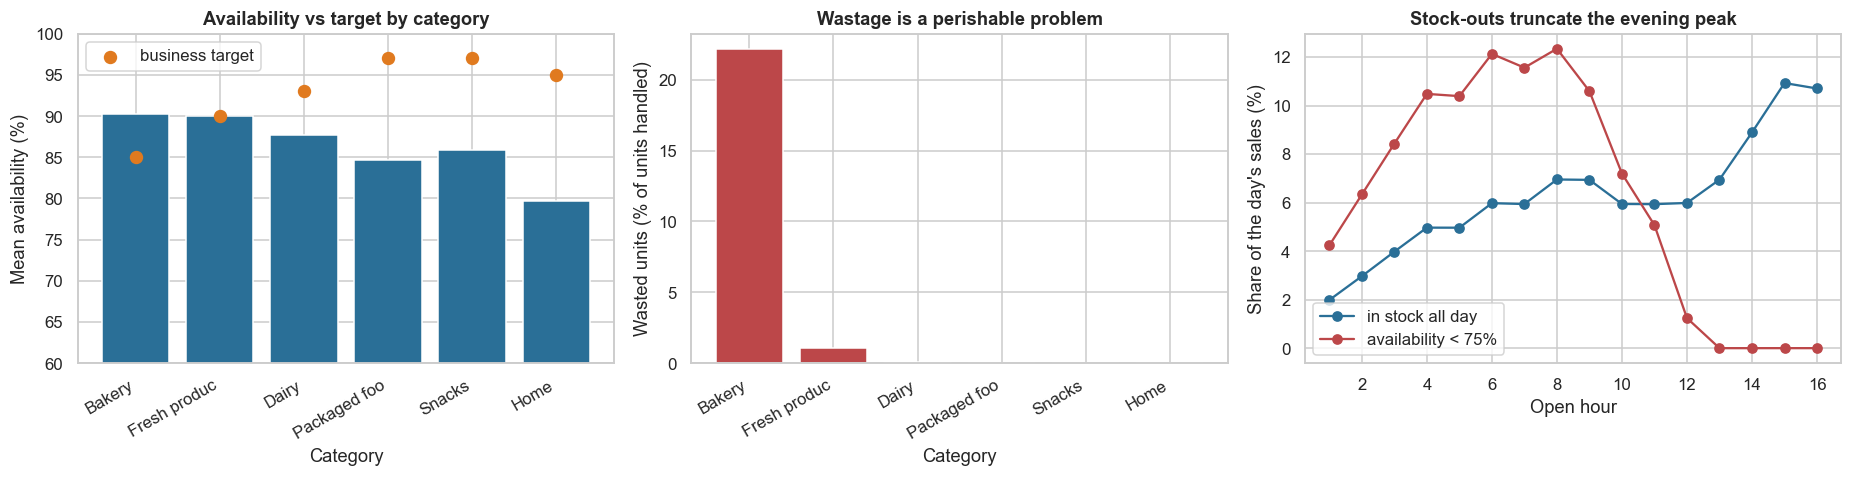

True demand / observed sales (simulation-only check of censoring): {'availability >= 95%': 1.01, '75% to 95%': 1.304, '< 75%': 1.932} | share of pod-SKU-days below 75% availability: 21.2%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5)); cn = gen.CAT_NAMES
g = df.groupby("category").agg(av=("avail_share", "mean"), sold=("units_sold", "sum"), wasted=("wasted_units", "sum")).reindex(cn); tg = SKM.groupby("category").target_availability.first().reindex(cn)
x = np.arange(6); axes[0].bar(x, g.av * 100, color="#2a6f97"); axes[0].scatter(x, tg * 100, color="#e07a1f", zorder=3, label="business target", s=60); axes[0].set_xticks(x); axes[0].set_xticklabels([c.split(" and")[0][:12] for c in cn], rotation=30, ha="right")
axes[0].set_ylim(60, 100); axes[0].set_xlabel("Category"); axes[0].set_ylabel("Mean availability (%)"); axes[0].set_title("Availability vs target by category"); axes[0].legend()
axes[1].bar(x, g.wasted / (g.sold + g.wasted) * 100, color="#bc4749"); axes[1].set_xticks(x); axes[1].set_xticklabels([c.split(" and")[0][:12] for c in cn], rotation=30, ha="right"); axes[1].set_xlabel("Category"); axes[1].set_ylabel("Wasted units (% of units handled)"); axes[1].set_title("Wastage is a perishable problem")
low = (AVf < 0.75) & VALID; hi = (AVf >= 0.999) & VALID
axes[2].plot(np.arange(1, 17), HOURLY[hi].sum(0) / HOURLY[hi].sum() * 100, marker="o", color="#2a6f97", label="in stock all day"); axes[2].plot(np.arange(1, 17), HOURLY[low].sum(0) / HOURLY[low].sum() * 100, marker="o", color="#bc4749", label="availability < 75%")
axes[2].set_xlabel("Open hour"); axes[2].set_ylabel("Share of the day's sales (%)"); axes[2].set_title("Stock-outs truncate the evening peak"); axes[2].legend()
plt.tight_layout(); plt.show()
ratio = pd.Series({lab: DTRUE[m & VALID].sum() / SOLD[m & VALID].sum() for lab, m in {"availability >= 95%": AVf >= 0.95, "75% to 95%": (AVf >= 0.75) & (AVf < 0.95), "< 75%": AVf < 0.75}.items()})
print("True demand / observed sales (simulation-only check of censoring):", ratio.round(3).to_dict(), "| share of pod-SKU-days below 75% availability:", f"{(AVf < 0.75)[VALID].mean():.1%}")

**Takeaway:** availability and wastage differ sharply by category (first two panels), and the third panel shows what censoring does: rows that stocked out lose their evening sales. Comparing true demand with observed sales (known only in the simulation), the ratio is **1.01** where availability was at least 95%, **1.30** for 75% to 95% and **1.93** below 75%. **21.2%** of pod-SKU-days are below 75% availability, so a model trained on raw sales sees a large share of truncated demand.

## 7. Statistical Analysis (core section)

### 7.1 Two forecasters and the usual metric (wMAPE on sales)

**(a) Why?** The planning chain starts with a forecast. We build two simple, fixed (untuned) models trained on days 14–48 and tested on days 49–83: **M1** = trailing 14-day mean of sales × a weekday factor (seasonal naive), **M2** = gradient-boosted trees (Poisson loss) on lags, an availability-adjusted lag, weekday, festival, promo, rain forecast, price, shelf life and category. Both see only **censored sales**. We compute **wMAPE on observed sales** (the usual metric), the same on **true demand** (possible only in the simulation) and the bias. Per-pod wMAPE differences are tested with a paired Wilcoxon test (48 pods).

#### Code

In [7]:
TRN, TST = (14, 49), (49, 84); MEAS = 3   # first 3 test days are warm-up for the replay and are excluded from outcomes
cs_s = np.concatenate([np.zeros((N, 1)), np.cumsum(SOLD, 1)], 1); cs_a = np.concatenate([np.zeros((N, 1)), np.cumsum(AVf, 1)], 1)
def build(d0, d1):
    d = np.arange(d0, d1); nd = len(d); w14 = cs_s[:, d] - cs_s[:, d - 14]
    f = dict(m14=w14 / 14, m7=(cs_s[:, d] - cs_s[:, d - 7]) / 7, last=SOLD[:, d - 1], lag7=SOLD[:, d - 7], adj14=w14 / np.maximum(cs_a[:, d] - cs_a[:, d - 14], 0.5), av14=(cs_a[:, d] - cs_a[:, d - 14]) / 14,
             expmean=cs_s[:, d] / d[None, :], dow=np.tile(DOW[d], (N, 1)), fest=np.tile(FESTD[d], (N, 1)), promo=PROMO[:, d], rain=RAIN[:, d], cat=np.tile(cat_n[:, None], (1, nd)),
             price=np.tile(price_row, (1, nd)), shelf=np.tile(np.minimum(Lrow, 4)[:, None], (1, nd)))
    return pd.DataFrame({k: v.reshape(-1) for k, v in f.items()})
Xtr, Xte = build(*TRN), build(*TST); ytr = SOLD[:, TRN[0]:TRN[1]].reshape(-1); vtr = VALID[:, TRN[0]:TRN[1]].reshape(-1)
yte = SOLD[:, TST[0]:].reshape(-1); dte = DTRUE[:, TST[0]:].reshape(-1); vte = VALID[:, TST[0]:].reshape(-1); avte = AVf[:, TST[0]:].reshape(-1)
nd_te = TST[1] - TST[0]; pod_te = np.repeat(np.arange(N) // gen.N_SKU, nd_te)
t0 = time.time(); m2 = HistGradientBoostingRegressor(loss="poisson", max_iter=200, learning_rate=0.1, random_state=SEED).fit(Xtr[vtr], ytr[vtr]); print(f"M2 fitted in {time.time() - t0:.0f}s")
dowf = np.ones((6, 7))
for c in range(6):
    for k in range(7):
        sel = vtr & (Xtr.cat.values == c); dowf[c, k] = ytr[sel & (Xtr.dow.values == k)].mean() / ytr[sel].mean()
F1 = (Xte.m14.values * dowf[Xte.cat.values.astype(int), Xte.dow.values.astype(int)]); F2 = m2.predict(Xte); F2tr = m2.predict(Xtr)
def wmape(F, y, m): return np.abs(F[m] - y[m]).sum() / y[m].sum()
rows = []
for name, F in (("M1 seasonal naive", F1), ("M2 gradient boosting", F2)):
    hi_av = vte & (avte >= 0.9)
    rows.append((name, wmape(F, yte, vte), wmape(F, yte, hi_av), wmape(F, dte, vte), F[vte].sum() / yte[vte].sum() - 1, F[vte].sum() / dte[vte].sum() - 1))
fc = pd.DataFrame(rows, columns=["model", "wMAPE vs sales", "wMAPE vs sales (availability >= 90% only)", "wMAPE vs TRUE demand", "bias vs sales", "bias vs TRUE demand"]).set_index("model")
pw = lambda F, y: np.array([np.abs(F[vte & (pod_te == p)] - y[vte & (pod_te == p)]).sum() / y[vte & (pod_te == p)].sum() for p in range(gen.N_PODS)])
d_sales = pw(F1, yte) - pw(F2, yte); d_true = pw(F1, dte) - pw(F2, dte)
print(f"Pod-level wMAPE (M1 − M2) on sales: mean {d_sales.mean():+.4f}, Wilcoxon p = {stats.wilcoxon(d_sales).pvalue:.2g}; on true demand: mean {d_true.mean():+.4f}, p = {stats.wilcoxon(d_true).pvalue:.2g}")
fc.round(4)

M2 fitted in 12s


Pod-level wMAPE (M1 − M2) on sales: mean -0.0015, Wilcoxon p = 0.0002; on true demand: mean -0.0019, p = 5e-08


,wMAPE vs sales,wMAPE vs sales (availability >= 90% only),wMAPE vs TRUE demand,bias vs sales,bias vs TRUE demand
model,,,,,
M1 seasonal naive,0.2385,0.2725,0.3995,-0.0030,-0.2373
M2 gradient boosting,0.2406,0.2694,0.4019,-0.0258,-0.2547


**Observation:** **M1 (seasonal naive) has the lower wMAPE on observed sales (0.2385 vs 0.2406)** and the pod-level difference is significant (Wilcoxon p = 0.0002), but the gap is tiny (0.15 points). On the subset where availability was at least 90%, **the order flips** (M1 0.2725, M2 0.2694): this is the documented flaw of evaluating only on high-availability days. Against true demand both models are far worse (0.3995 and 0.4019) and both **under-forecast by 24% to 25%** (bias -0.237 and -0.255), while their bias against sales looks small (-0.3% and -2.6%). Training on censored sales hides how short the forecasts are. M2 gives no gain over a trailing mean here, and we do not claim one; it is trained on the same censored sales.

### 7.2 Does the offline metric match the business outcome? Estimated availability and wastage (EA / EW)

**(a) Why?** The business cares about availability and wastage once a model drives the **purchase order (PO)**. For each model we set the day's PO target = forecast × the category buffer (the same rule in both arms). The **truth** (a one-day counterfactual with stock = PO target, using the hidden hourly demand) is available only in the simulation. From the **logs alone** we estimate it two ways, following the documented idea: **simple EA** = observed availability × (predicted stock ÷ observed sales), capped at 1; **hourly EA** = find the hour at which the predicted stock would have sold out using observed hourly sales, or extend the observed in-stock hours at the day's **median hourly sales** if the prediction exceeds what was sold. **EW** (leftover units) is the stock that would remain.

**(b) Assumptions:** hourly sales are observed; demand per hour is steady while out of stock (checked in 7.2 by comparing to the truth); the estimator is a **one-day** counterfactual with no carry-over.

**(c) Tests:** bias and error of each estimator against the truth, pod-bootstrap 95% CI (2,000 resamples) for the **M2 − M1 lift**.

#### Code

In [8]:
BUF = gen.LEGACY_BUFFER[cat_n][:, None]; Hts = H[:, TST[0]:]; Sts = SOLD[:, TST[0]:]; Ats = AVf[:, TST[0]:]; HSts = HOURLY[:, TST[0]:]; Vts = VALID[:, TST[0]:].copy(); Vts[:, :MEAS] = False
def tgt_from(F): return np.maximum(np.ceil(F.reshape(N, nd_te) * BUF), 1)
T1, T2 = tgt_from(F1), tgt_from(F2)
def ea_est(T, S, A, HS):
    Ah = A * 16; cs = np.cumsum(HS, axis=2).astype(float); simple = np.where(S > 0, np.minimum(1, A * T / np.maximum(S, 1e-9)), A)
    instock = np.arange(16)[None, None, :] < np.ceil(Ah - 1e-9)[..., None]; med = np.nan_to_num(np.nanmedian(np.where(instock, HS, np.nan), axis=2))
    reach = cs >= T[..., None] - 1e-9; h = reach.argmax(2); prev = np.where(h > 0, np.take_along_axis(cs, np.maximum(h - 1, 0)[..., None], 2)[..., 0], 0.0); hsh = np.take_along_axis(HS.astype(float), h[..., None], 2)[..., 0]
    pos = h + np.where(hsh > 0, (T - prev) / np.maximum(hsh, 1e-9), 1.0); ea_a = np.minimum(pos, 16) / 16
    extra = np.where(med > 0, (T - S) / np.maximum(med, 1e-9), 0.0); ea_b = np.where(A >= 0.999, 1.0, np.minimum(1.0, (Ah + extra) / 16))
    hourly = np.where(T <= S + 1e-9, ea_a, ea_b); Sest = np.where(T <= S + 1e-9, T, np.minimum(T, S + np.maximum(hourly * 16 - Ah, 0) * med)); return simple, hourly, T - Sest
def podmean(x, mask): return (x * mask).reshape(gen.N_PODS, gen.N_SKU, -1).sum((1, 2)) / mask.reshape(gen.N_PODS, gen.N_SKU, -1).sum((1, 2))
def ci_mean(x, B=2000): bs = x[RNG.integers(0, len(x), (B, len(x)))].mean(1); return x.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
res = {}
for nm, T in (("M1", T1), ("M2", T2)):
    s_true, a_true, left_true = gen.oneday_truth(Hts.astype(float), T); a_simple, a_hour, left_est = ea_est(T, Sts, Ats, HSts)
    res[nm] = dict(true=podmean(a_true, Vts), simple=podmean(a_simple, Vts), hourly=podmean(a_hour, Vts), left_true=podmean(left_true, Vts), left_est=podmean(left_est, Vts))
rows = []
for k in ("true", "simple", "hourly"):
    m1, m2_ = res["M1"][k], res["M2"][k]; lift = m2_ - m1; mu, lo, hi = ci_mean(lift); rows.append((k, m1.mean(), m2_.mean(), mu * 100, lo * 100, hi * 100))
ea_tab = pd.DataFrame(rows, columns=["EA version", "M1 availability", "M2 availability", "M2 − M1 lift (pp)", "CI low (pp)", "CI high (pp)"]).set_index("EA version")
bias = {k: (res["M1"][k] - res["M1"]["true"]).mean() * 100 for k in ("simple", "hourly")}; rmse = {k: np.sqrt(np.mean((res["M1"][k] - res["M1"]["true"]) ** 2)) * 100 for k in ("simple", "hourly")}
print(f"Estimator bias vs truth for M1 (pp of availability): simple {bias['simple']:+.2f}, hourly {bias['hourly']:+.2f}; pod-level RMSE (pp): simple {rmse['simple']:.2f}, hourly {rmse['hourly']:.2f}")
print(f"Leftover units per pod-SKU-day, M1: truth {res['M1']['left_true'].mean():.3f}, estimated {res['M1']['left_est'].mean():.3f}; M2: truth {res['M2']['left_true'].mean():.3f}, estimated {res['M2']['left_est'].mean():.3f}")
ea_tab.round(4)

Estimator bias vs truth for M1 (pp of availability): simple +0.21, hourly -0.54; pod-level RMSE (pp): simple 0.23, hourly 0.62
Leftover units per pod-SKU-day, M1: truth 1.741, estimated 1.840; M2: truth 1.602, estimated 1.697


,M1 availability,M2 availability,M2 − M1 lift (pp),CI low (pp),CI high (pp)
EA version,,,,,
true,0.8532,0.8493,-0.3896,-0.4553,-0.3286
simple,0.8552,0.8504,-0.4882,-0.5755,-0.4166
hourly,0.8478,0.8441,-0.3690,-0.4241,-0.3205


**Observation:** the estimators work, with different strengths. For M1 the **simple EA is biased by +0.21 pp** (pod RMSE 0.23 pp) and the **hourly EA by -0.54 pp** (RMSE 0.62 pp), so on levels the simple version is closer here. For the quantity that drives the decision, the **M2 - M1 lift**, the truth is **-0.39 pp** (CI -0.46 to -0.33); simple EA says -0.49 pp (CI -0.58 to -0.42) and **hourly EA -0.37 pp (CI -0.42 to -0.32)**, so hourly is closer on the lift. Both get the sign and the ranking right, and both show M2 slightly worse on availability, as the all-rows wMAPE did. Estimated leftover units are about 0.1 per pod-SKU-day too high (M1 1.84 vs truth 1.74; M2 1.70 vs 1.60). H1 is only partly supported: wMAPE on all rows and EA agree on the ranking, but wMAPE on high-availability rows would have chosen the other model.

### 7.3 The newsvendor core: how much to order per category

**(a) Why?** With demand uncertainty, the profit-maximising order stocks up to the demand quantile equal to the **critical ratio** CR = Cu ÷ (Cu + Co), where **Cu** is the cost of one unit too few (margin + 50% of price goodwill) and **Co** the cost of one unit too many (purchase cost for perishables; about 10 days of holding cost for non-perishables). We build the order target from the **M2 forecast** plus the demand **distribution**: negative binomial with mean = forecast and dispersion fitted by least squares on training days where availability was ≥ 95% (an optimistic selection; the fit is flagged as a limitation). We compare the newsvendor family (target = demand quantile q) with the **fixed-buffer** family (target = forecast × m).

**(b) How we test:** each ordering rule is **replayed on the twin** (same true demand, same vendor shortfalls, FIFO ageing, carry-over). For each category we pick the best q and best m on the **even-numbered pods** and report profit on the **odd-numbered pods** (24 paired pods; Wilcoxon; Holm across 6 categories), so tuning does not flatter the result. We also check the textbook q = CR against the empirical profit-maximising q.

#### Code

In [9]:
Cu = (price_row - cost_row) + gen.GOODWILL * price_row; Co = np.where(nonper[:, None], cost_row * gen.HOLD * 10, cost_row); CRrow = (Cu / (Cu + Co))[:, 0]; CRcat = np.array([CRrow[cat_n == c].mean() for c in range(6)])
# the textbook CR is exact for a 1-day shelf life only; for longer lives leftovers are not lost, so the real optimum is higher
Ftr = np.maximum(F2tr, 0.05); hi_tr = vtr & (Xtr.av14.values > 0) & (AVf[:, TRN[0]:TRN[1]].reshape(-1) >= 0.95); rhat = np.zeros(6); bhat = np.zeros(6)
for c in range(6):
    s = hi_tr & (Xtr.cat.values == c); b = np.sum(((ytr[s] - Ftr[s]) ** 2 - Ftr[s]) * Ftr[s] ** 2) / np.sum(Ftr[s] ** 4); bhat[c] = max(b, 0.02); rhat[c] = np.clip(1 / bhat[c], 1, 50)
Fte2 = np.maximum(F2.reshape(N, nd_te), 0.05); r_row = rhat[cat_n][:, None]
def T_nb(q): return np.maximum(nbinom.ppf(q, r_row, r_row / (r_row + Fte2)), 1)
def T_fix(m): return np.maximum(np.ceil(Fte2 * m), 1)
def replay(T, hourly=False):
    return gen.simulate(Hts, T, Lrow, nonper, FILLU[:, TST[0]:], collect_hourly=hourly)
def podcat(M): return M[:, MEAS:].reshape(gen.N_PODS, 6, 20, -1).sum((2, 3))
def econ(sim):
    sold, wasted, lost, op = sim["sold"], sim["wasted"], sim["lost"], sim["opening"]; prof = sold * (price_row - cost_row) - wasted * cost_row - gen.GOODWILL * price_row * lost - gen.HOLD * cost_row * np.maximum(op - sold, 0)
    return dict(profit=podcat(prof), gmv=podcat(sold * price_row), wval=podcat(wasted * cost_row), avail=podcat(sim["avail"]) / (20 * (nd_te - MEAS)))
QG = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98, 0.995]; MG = [0.9, 1.0, 1.1, 1.2, 1.3, 1.45, 1.6, 1.8]
t0 = time.time(); E_nb = {q: econ(replay(T_nb(q))) for q in QG}; E_fx = {m: econ(replay(T_fix(m))) for m in MG}; print(f"{len(QG) + len(MG)} policy replays in {time.time() - t0:.0f}s")
pdays = gen.N_PODS * (nd_te - MEAS); ev = np.arange(gen.N_PODS) % 2 == 0; od = ~ev; rows = []; pvals = []
for c in range(6):
    bq = max(QG, key=lambda q: E_nb[q]["profit"][ev, c].sum()); bm = max(MG, key=lambda m: E_fx[m]["profit"][ev, c].sum())
    a, b = E_nb[bq]["profit"][od, c], E_fx[bm]["profit"][od, c]; p = stats.wilcoxon(a, b).pvalue; pvals.append(p); allq = max(QG, key=lambda q: E_nb[q]["profit"][:, c].sum())
    rows.append((gen.CAT_NAMES[c], CRcat[c], bq, allq, bm, a.sum() / (od.sum() * (nd_te - MEAS)) / 1, b.sum() / (od.sum() * (nd_te - MEAS)), (a - b).mean() / (nd_te - MEAS) * 20 / 20, E_nb[bq]["avail"][od, c].mean(), E_fx[bm]["avail"][od, c].mean(),
                 E_nb[bq]["wval"][od, c].sum() / E_nb[bq]["gmv"][od, c].sum(), E_fx[bm]["wval"][od, c].sum() / E_fx[bm]["gmv"][od, c].sum(), SKM.target_availability[SKM.category == gen.CAT_NAMES[c]].iloc[0], p))
nv = pd.DataFrame(rows, columns=["category", "critical ratio", "best q (even pods)", "best q (all pods)", "best buffer m (even pods)", "₹ profit/pod-day NV (odd pods)", "₹ profit/pod-day fixed", "Δ ₹/pod-day (mean)", "avail NV", "avail fixed", "waste % GMV NV", "waste % GMV fixed", "target avail", "Wilcoxon p"]).set_index("category")
nv["p_holm"] = multipletests(nv["Wilcoxon p"], method="holm")[1]
print("Dispersion fitted vs true (simulation only):", {gen.CAT_NAMES[c].split(' and')[0][:9]: (round(rhat[c], 1), gen.CATS[c][4]) for c in range(6)})
nv.round(4)

16 policy replays in 54s


Dispersion fitted vs true (simulation only): {'Bakery': (np.float64(17.0), 6), 'Fresh pro': (np.float64(24.5), 8), 'Dairy': (np.float64(49.3), 10), 'Packaged ': (np.float64(50.0), 12), 'Snacks': (np.float64(50.0), 12), 'Home': (np.float64(50.0), 5)}


,critical ratio,best q (even pods),best q (all pods),best buffer m (even pods),₹ profit/pod-day NV (odd pods),₹ profit/pod-day fixed,Δ ₹/pod-day (mean),avail NV,avail fixed,waste % GMV NV,waste % GMV fixed,target avail,Wilcoxon p,p_holm
category,,,,,,,,,,,,,,
Bakery and ready-to-eat,0.5404,0.8000,0.8000,1.2000,34.3276,48.9814,-14.6538,0.8932,0.8766,0.1643,0.1497,0.8500,0.1208,0.1208
Fresh produce,0.4949,0.9800,0.9800,1.8000,"3,021.8043","3,090.2443",-68.4400,0.9720,0.9676,0.0295,0.0285,0.9000,0.0005,0.0010
Dairy and eggs,0.4541,0.9950,0.9950,1.8000,"2,607.2614","2,403.0538",204.2076,0.9837,0.9621,0.0054,0.0016,0.9300,0.0000,0.0000
Packaged food,0.9571,0.9950,0.9950,1.8000,"3,283.1626","2,666.7347",616.4279,0.9837,0.9453,0.0000,0.0000,0.9700,0.0000,0.0000
Snacks and beverages,0.9582,0.9950,0.9950,1.8000,"2,117.8239","1,920.7971",197.0268,0.9821,0.9527,0.0000,0.0000,0.9700,0.0000,0.0000
Home and personal care,0.9639,0.9950,0.9950,1.8000,"2,599.0318","1,264.8213","1,334.2106",0.9777,0.8796,0.0000,0.0000,0.9500,0.0000,0.0000


**Observation:** the critical ratio is **0.54 for bakery, 0.49 for produce, 0.45 for dairy and about 0.96 for the three non-perishable categories**. The best quantile on the even pods was **0.80 for bakery, 0.98 for produce and 0.995 for dairy** and the non-perishables, far above the critical ratio for 2 to 3 day items, because unsold units carry over to the next day. The fitted dispersion is too high (17 to 50 against true values of 5 to 12) because it was fitted on high-availability days, which makes the negative-binomial buffer thinner than it should be. On the held-out odd pods the newsvendor family earned more than the best fixed buffer for **dairy (+₹204 per category-pod-day), packaged food (+₹616), snacks (+₹197) and home care (+₹1,334)**, all with Holm p < 0.001, and met every category availability target (for example dairy 98.4% vs 96.2% for the fixed buffer, target 93%). It was **worse for fresh produce (-₹68, Holm p = 0.001)** and indistinguishable for bakery (-₹15, p = 0.12). For the non-perishables, both families chose the edge of the grid (q = 0.995, m = 1.8), so the gain mostly says the legacy buffer of 1.10 is too thin when holding cost is small; the grid should be widened before relying on exact values. H3 is supported for four of six categories and rejected for produce.

#### Frontier chart

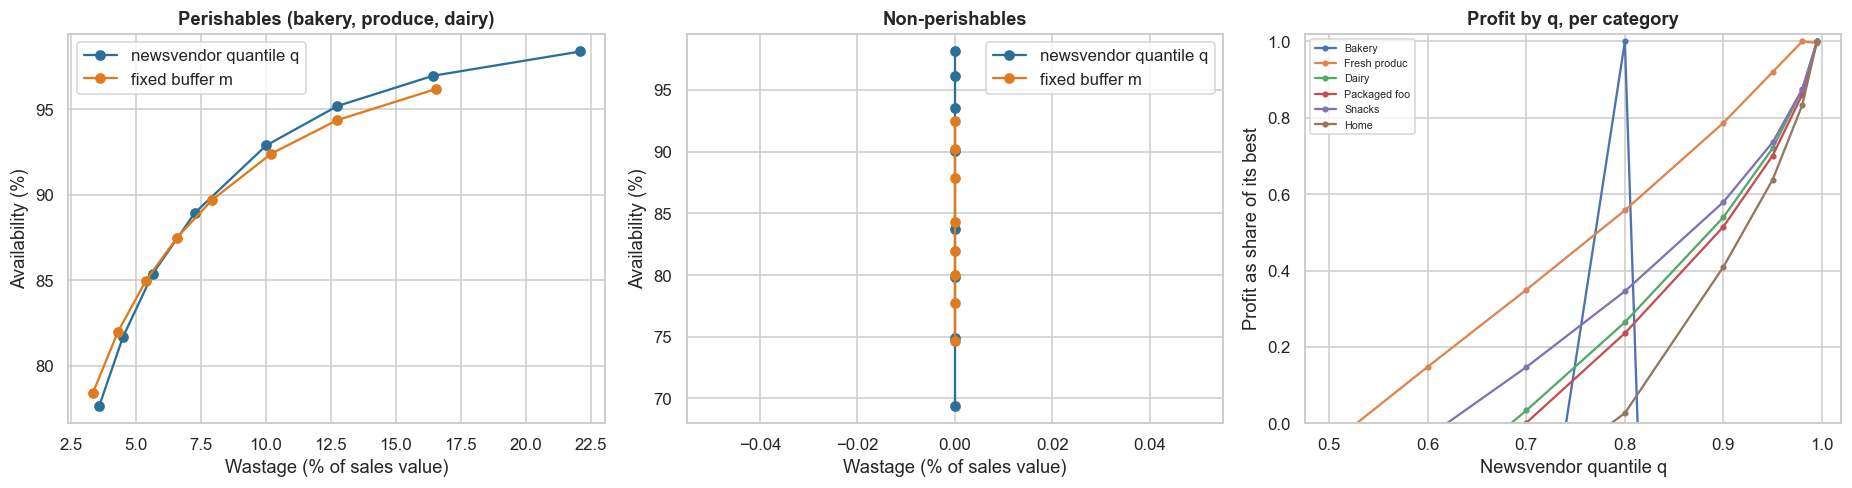

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, cats, ttl in ((axes[0], [0, 1, 2], "Perishables (bakery, produce, dairy)"), (axes[1], [3, 4, 5], "Non-perishables")):
    for E, key, col, lab in ((E_nb, QG, "#2a6f97", "newsvendor quantile q"), (E_fx, MG, "#e07a1f", "fixed buffer m")):
        xs = [E[k]["wval"][:, cats].sum() / E[k]["gmv"][:, cats].sum() * 100 for k in key]; ys = [E[k]["avail"][:, cats].mean() * 100 for k in key]; ax.plot(xs, ys, marker="o", color=col, label=lab)
    ax.set_xlabel("Wastage (% of sales value)"); ax.set_ylabel("Availability (%)"); ax.set_title(ttl); ax.legend()
for c in range(6):
    pr = np.array([E_nb[q]["profit"][:, c].sum() for q in QG]); axes[2].plot(QG, pr / pr.max(), marker=".", label=gen.CAT_NAMES[c].split(" and")[0][:12])
axes[2].set_ylim(0.0, 1.02); axes[2].set_xlabel("Newsvendor quantile q"); axes[2].set_ylabel("Profit as share of its best"); axes[2].set_title("Profit by q, per category"); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Takeaway:** in the perishable panel the two curves are close: for the same wastage, the newsvendor sweep and the fixed-buffer sweep give similar availability, so for bread, produce and dairy the order rule matters less than where on the curve you choose to sit. In the non-perishable panel the newsvendor curve sits clearly higher. The profit curves (right) are flat near their best for most categories and fall away sharply on the low side, so ordering too little is the expensive mistake once a lost sale costs 50% of price.

### 7.4 The randomised pod experiment: leak-free EA, leaky EA and the actual lift

**(a) Why?** The documented validation runs two models in two randomly chosen sets of pods and checks the offline estimate against the actual lift. We repeat it on the twin: **24 pods are randomly assigned M2, 24 stay on M1** (same PO buffer rule), and the replay gives every pod's actual outcome. Each model's EA is estimated from the logs of the pods where it was **not** used (**leak-free**) and, for contrast, where it **was** used (**leaky**). Because the twin can run **both** models on **every** pod with the same demand, we also get the **paired oracle lift**, which the real company cannot see.

**(b) Tests:** Welch and **ANCOVA** (adjusting for each pod's pre-period availability) for the actual lift; bootstrap CIs for the EA lifts. The EA estimators come from 7.2.

#### Code

In [11]:
arm = np.zeros(gen.N_PODS, int); arm[RNG.permutation(gen.N_PODS)[:24]] = 1     # 1 = M2
S1, S2 = replay(T1, True), replay(T2, True); E1, E2 = econ(S1), econ(S2)
pod_av = lambda E: E["avail"].mean(1); pod_w = lambda E: E["wval"].sum(1) / E["gmv"].sum(1); pod_p = lambda E: E["profit"].sum(1) / (nd_te - MEAS)
act = {k: np.where(arm == 1, f(E2), f(E1)) for k, f in (("avail", pod_av), ("waste", pod_w), ("profit", pod_p))}
pre = AVf[:, 21:49].reshape(gen.N_PODS, gen.N_SKU, -1).mean((1, 2))
def lift_tab(y):
    d = y[arm == 1].mean() - y[arm == 0].mean(); t = stats.ttest_ind(y[arm == 1], y[arm == 0], equal_var=False); se = np.sqrt(y[arm == 1].var(ddof=1) / 24 + y[arm == 0].var(ddof=1) / 24)
    m = sm.OLS(y, sm.add_constant(np.c_[arm, pre])).fit(); return d, d - 1.96 * se, d + 1.96 * se, t.pvalue, m.params[1], *m.conf_int()[1], m.pvalues[1], m
ta = lift_tab(act["avail"]); tw = lift_tab(act["waste"]); tp = lift_tab(act["profit"])
orc = {k: f(E2) - f(E1) for k, f in (("avail", pod_av), ("waste", pod_w), ("profit", pod_p))}
def ea_for(T, S_sim, pods_mask, kind):
    a_s, a_h, l_ = ea_est(T, S_sim["sold"], S_sim["avail"], S_sim["hourly"]); x = a_h if kind == "hourly" else a_s; return podmean(x, Vts)[pods_mask]
rows = []
def add(name, vals_hi, vals_lo): d = vals_hi.mean() - vals_lo.mean(); bs = [vals_hi[RNG.integers(0, len(vals_hi), len(vals_hi))].mean() - vals_lo[RNG.integers(0, len(vals_lo), len(vals_lo))].mean() for _ in range(2000)]; rows.append((name, d * 100, np.percentile(bs, 2.5) * 100, np.percentile(bs, 97.5) * 100))
for kind in ("hourly", "simple"):
    add(f"EA {kind}, leak-free (M2 on M1 pods − M1 on M2 pods)", ea_for(T2, S1, arm == 0, kind), ea_for(T1, S2, arm == 1, kind))
    add(f"EA {kind}, LEAKY (M2 on M2 pods − M1 on M1 pods)", ea_for(T2, S2, arm == 1, kind), ea_for(T1, S1, arm == 0, kind))
add("EA hourly, same pods (all pods' M1 logs)", ea_for(T2, S1, np.ones(48, bool), "hourly"), ea_for(T1, S1, np.ones(48, bool), "hourly"))
mu, lo, hi = ci_mean(orc["avail"]); rows.append(("Paired oracle lift, full replay with carry-over (all pods)", mu * 100, lo * 100, hi * 100)); rows.append(("Actual lift in the 24 v 24 experiment, ANCOVA", ta[4] * 100, ta[5] * 100, ta[6] * 100))
rows.append(("Actual lift in the 24 v 24 experiment, difference in means", ta[0] * 100, ta[1] * 100, ta[2] * 100))
ex = pd.DataFrame(rows, columns=["availability lift estimate", "pp", "CI low", "CI high"]).set_index("availability lift estimate")
print(f"Arms: {arm.sum()} v {(1 - arm).sum()} pods; pre-period availability balance: M2 pods {pre[arm == 1].mean():.4f}, M1 pods {pre[arm == 0].mean():.4f}")
print(f"Availability: diff p = {ta[3]:.3g}, ANCOVA p = {ta[7]:.3g} | wastage (% of sales value): diff {tw[0] * 100:+.2f} pp (CI {tw[1] * 100:+.2f} to {tw[2] * 100:+.2f}) | profit/pod-day: diff ₹{tp[0]:,.0f} (CI ₹{tp[1]:,.0f} to ₹{tp[2]:,.0f}) | oracle paired profit ₹{orc['profit'].mean():,.0f}, waste {orc['waste'].mean() * 100:+.2f} pp")
ex.round(3)

Arms: 24 v 24 pods; pre-period availability balance: M2 pods 0.8562, M1 pods 0.8572
Availability: diff p = 0.0773, ANCOVA p = 0.016 | wastage (% of sales value): diff -0.49 pp (CI -0.83 to -0.14) | profit/pod-day: diff ₹-462 (CI ₹-1,411 to ₹488) | oracle paired profit ₹-333, waste -0.34 pp


,pp,CI low,CI high
availability lift estimate,,,
"EA hourly, leak-free (M2 on M1 pods − M1 on M2 pods)",-0.1210,-0.8670,0.6630
"EA hourly, LEAKY (M2 on M2 pods − M1 on M1 pods)",-0.5150,-1.3080,0.2940
"EA simple, leak-free (M2 on M1 pods − M1 on M2 pods)",-0.4150,-1.0750,0.1910
"EA simple, LEAKY (M2 on M2 pods − M1 on M1 pods)",-0.5380,-1.2080,0.1270
"EA hourly, same pods (all pods' M1 logs)",-0.7240,-1.2830,-0.1720
"Paired oracle lift, full replay with carry-over (all pods)",-0.4270,-0.4930,-0.3640
"Actual lift in the 24 v 24 experiment, ANCOVA",-0.5010,-0.9040,-0.0980
"Actual lift in the 24 v 24 experiment, difference in means",-0.5760,-1.2010,0.0490


**Observation:** in the randomised 24 v 24 experiment **M2 lowered availability by 0.58 pp** on the simple difference (Welch p = 0.077) and **by 0.50 pp after adjusting for pre-period availability** (ANCOVA p = 0.016); wastage was **0.49 pp of sales value lower** (CI -0.83 to -0.14) and profit per pod-day was not significantly different (₹-462, CI ₹-1,411 to ₹488). The paired oracle on all pods agrees on the direction: **-0.43 pp availability** (CI -0.49 to -0.36), wastage -0.34 pp, profit ₹-333 per pod-day. The offline EA lifts have the right sign but wide intervals: **leak-free hourly -0.12 pp (CI -0.87 to +0.66)**, leaky hourly -0.52 pp (CI -1.31 to +0.29), simple leak-free -0.42 pp, and the same-pod version -0.72 pp (CI -1.28 to -0.17). All of these intervals include or sit near the actual lift, so H4 is **not rejected, but this experiment cannot show that leak-free beats leaky**; the leaky estimate was in fact closer to the actual lift here. M2 is a small step back on availability in exchange for less wastage, not an improvement.

#### Forest chart of the lift estimates

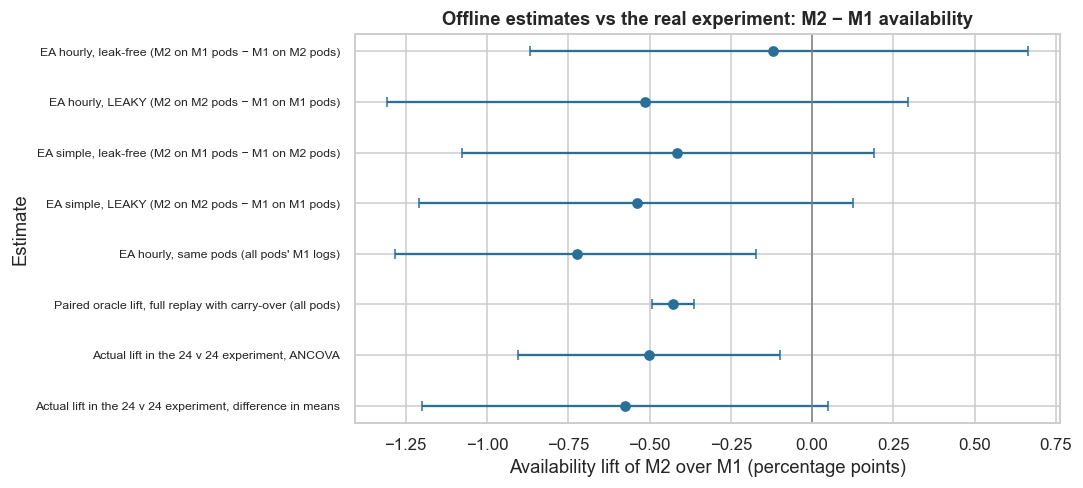

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.6)); yy = np.arange(len(ex))[::-1]
ax.errorbar(ex["pp"], yy, xerr=[ex["pp"] - ex["CI low"], ex["CI high"] - ex["pp"]], fmt="o", color="#2a6f97", capsize=3); ax.axvline(0, color="grey", lw=1)
ax.set_yticks(yy); ax.set_yticklabels([s[:58] for s in ex.index], fontsize=8); ax.set_xlabel("Availability lift of M2 over M1 (percentage points)"); ax.set_ylabel("Estimate"); ax.set_title("Offline estimates vs the real experiment: M2 − M1 availability")
plt.tight_layout(); plt.show()

**Takeaway:** every estimate is on the same side of zero, but the pod-level estimates (EA on separate pod sets, and the 24 v 24 difference) have intervals roughly ten times wider than the paired oracle, which can only be built in a simulation. A 48-pod experiment can confirm a direction, not a half-point effect.

### 7.5 How many pods does such an experiment need?

With 48 pods the experiment above can detect only large effects. Using the pod-level standard deviation of the availability outcome (raw and after ANCOVA adjustment for pre-period availability), we compute **pods per arm** to detect lifts of 0.5, 1, 2 and 3 percentage points (80% power, α = 0.05, two-sided; n = 2(1.96+0.84)² σ² ÷ δ²). Because pods in a cluster share demand, we also estimate the **intra-cluster correlation (ICC)** and the **design effect** if randomisation had to be by cluster of 6 pods.

#### Code

In [13]:
sd_raw = act["avail"].std(ddof=1); sd_adj = np.sqrt(ta[-1].scale); clus = np.arange(gen.N_PODS) // gen.PER_CLUSTER if hasattr(gen, "PER_CLUSTER") else np.arange(gen.N_PODS) // 6
pre_pod = pre; g_ = pd.Series(pre_pod).groupby(clus); msb = 6 * g_.mean().var(ddof=1); msw = g_.var(ddof=1).mean(); icc = max((msb - msw) / (msb + 5 * msw), 0.0); deff = 1 + 5 * icc
rows = [(f"{d:.1f} pp", int(np.ceil(2 * 2.8 ** 2 * sd_raw ** 2 / (d / 100) ** 2)), int(np.ceil(2 * 2.8 ** 2 * sd_adj ** 2 / (d / 100) ** 2)), int(np.ceil(2 * 2.8 ** 2 * sd_adj ** 2 / (d / 100) ** 2 * deff))) for d in (0.5, 1, 2, 3)]
pw_ = pd.DataFrame(rows, columns=["lift to detect", "pods per arm (raw)", "pods per arm (ANCOVA)", "pods per arm, cluster-randomised (design effect)"]).set_index("lift to detect")
mde = 2.8 * sd_adj * np.sqrt(2 / 24) * 100
print(f"Pod-level SD of availability: raw {sd_raw * 100:.2f} pp, after ANCOVA {sd_adj * 100:.2f} pp | pre-period correlation with outcome r = {np.corrcoef(pre, act['avail'])[0, 1]:.2f} | ICC by cluster (pre-period) = {icc:.3f}, design effect {deff:.2f} | minimum detectable lift with 24 v 24 pods: {mde:.2f} pp")
pw_

Pod-level SD of availability: raw 1.13 pp, after ANCOVA 0.69 pp | pre-period correlation with outcome r = 0.77 | ICC by cluster (pre-period) = 0.294, design effect 2.47 | minimum detectable lift with 24 v 24 pods: 0.56 pp


,pods per arm (raw),pods per arm (ANCOVA),"pods per arm, cluster-randomised (design effect)"
lift to detect,,,
0.5 pp,81,31,75
1.0 pp,21,8,19
2.0 pp,6,2,5
3.0 pp,3,1,3


**Observation:** pod-level availability has a standard deviation of **1.13 pp**, falling to **0.69 pp** after adjusting for pre-period availability (correlation 0.77), which cuts the pods needed by about 60%. With 24 pods per arm the **minimum detectable lift is 0.56 pp**. To detect **1 pp** you need **21 pods per arm raw, 8 after adjustment, 19 if you must randomise by cluster of 6** (ICC 0.29, design effect 2.47); for 0.5 pp the numbers are 81, 31 and 75. Pod behaviour is strongly clustered, so cluster-level randomisation costs about 2.5 times the pods. Adjusting for pre-period outcomes is the cheapest way to shrink a store experiment.

### 7.6 Picking, part 1: what drives time-to-pack?

**(a) Why?** The batching decision trades **setup and walking saved** against a **bigger basket**. That needs a time-to-pack model. From the order log (single-order picks under round-robin assignment) we regress pick-and-pack seconds on the number of items, the number of distinct **zones** visited and weight. Heteroscedasticity-robust (HC3) errors; the simulation's true per-item (10 s) and per-zone (24 s) times serve as a check.

#### Code

In [14]:
pk = picks.copy(); ols = smf.ols("pick_pack_sec ~ n_items + n_zones + weight_kg", data=pk).fit(cov_type="HC3")
resid = ols.resid; bp = sm.stats.diagnostic.het_breuschpagan(resid, ols.model.exog)[1]
print(f"Orders: {len(pk):,} | R² = {ols.rsquared:.3f} | residual skew {stats.skew(resid):.2f} | Breusch-Pagan p = {bp:.2g}")
ct = pd.DataFrame({"coef (s)": ols.params, "CI low": ols.conf_int()[0], "CI high": ols.conf_int()[1], "p": ols.pvalues}); ct["true value in simulation (s)"] = [gen.SETUP + gen.PACK, gen.T_ITEM, gen.T_ZONE, 0.0]
ct.round(3)

Orders: 57,997 | R² = 0.737 | residual skew 0.84 | Breusch-Pagan p = 0


,coef (s),CI low,CI high,p,true value in simulation (s)
Intercept,38.4960,37.7500,39.2420,0.0000,38.0000
n_items,10.1620,9.8000,10.5230,0.0000,10.0000
n_zones,24.2210,23.7240,24.7190,0.0000,24.0000
weight_kg,-0.2280,-0.8430,0.3870,0.4680,0.0000


**Observation:** the time-to-pack model fits well (**R² = 0.737**) and recovers the simulated costs: **10.2 s per item** (CI 9.8 to 10.5; true 10), **24.2 s per zone** (CI 23.7 to 24.7; true 24) and a fixed 38.5 s (true 38). Weight adds nothing (-0.2 s per kg, p = 0.47). Residuals are right-skewed (0.84) and the variance rises with basket size (Breusch-Pagan p < 1e-10), so we used robust errors. The zone term is large: each extra aisle costs as much as 2.4 items, which is why similar baskets are worth batching.

### 7.7 Picking, part 2: when does batching up to 2 orders help?

**(a) Why?** The documented rule: batch up to 2 orders when free pickers are fewer than unassigned orders. Our event simulator applies exactly that: when a picker frees up and more orders are waiting than pickers are free, the oldest order is paired with the **most similar** of the next 8 waiting orders (zone Jaccard similarity ≥ θ, at most 14 items and 12 kg together). Pairs share setup and walking but pay a sorting step, and mixed baskets raise the packing-error rate. We replay **30 paired order-days** (same orders for every policy) at 4 to 7 pickers and θ = 0.2, 0.4, 0.6, and compare with **no batching**.

**(b) Tests:** per setting, paired differences of daily means with t-based 95% CI and Wilcoxon; Holm across the 12 comparisons; a regression of the θ = 0.2 gain on staffing for the interaction (H5b). Error cost ₹120 per packing error (assumption).

#### Code

In [15]:
KS, THS, ND = [4, 5, 6, 7], [None, 0.2, 0.4, 0.6], 30
orders = [gen.gen_orders(np.random.default_rng(1000 + s)) for s in range(ND)]; rows = []; t0 = time.time()
for K in KS:
    for th in THS:
        for s, o in enumerate(orders):
            r = gen.sim_picking(o, K, th); rows.append((K, "none" if th is None else f"θ={th}", s, r["assign_wait"].mean(), r["order_to_ready"].mean(), np.percentile(r["order_to_ready"], 90), r["batched"].mean(), r["error"].sum(), r["busy"] / 3600))
bt = pd.DataFrame(rows, columns=["pickers", "policy", "day", "assign_wait", "order_to_ready", "p90_ready", "batched_share", "errors", "busy_hours"]); print(f"{len(bt)} simulated pod-days in {time.time() - t0:.0f}s")
rows = []
for K in KS:
    base = bt[(bt.pickers == K) & (bt.policy == "none")].sort_values("day")
    for pol in ("θ=0.2", "θ=0.4", "θ=0.6"):
        cur = bt[(bt.pickers == K) & (bt.policy == pol)].sort_values("day"); d = cur.order_to_ready.values - base.order_to_ready.values; dw = cur.assign_wait.values - base.assign_wait.values; de = cur.errors.values - base.errors.values
        se = d.std(ddof=1) / np.sqrt(ND); tc = stats.t.ppf(0.975, ND - 1); rows.append((K, pol, base.order_to_ready.mean(), d.mean(), d.mean() - tc * se, d.mean() + tc * se, dw.mean(), cur.batched_share.mean(), de.mean(), stats.wilcoxon(cur.order_to_ready.values, base.order_to_ready.values).pvalue))
bs = pd.DataFrame(rows, columns=["pickers", "policy", "baseline order-to-ready (s)", "Δ order-to-ready (s)", "CI low", "CI high", "Δ assign wait (s)", "share batched", "Δ errors/day", "Wilcoxon p"]); bs["p_holm"] = multipletests(bs["Wilcoxon p"], method="holm")[1]
g2 = bs[bs.policy == "θ=0.2"]; sl = stats.linregress(g2.pickers, g2["Δ order-to-ready (s)"]); print(f"Gain from θ=0.2 vs staffing: slope {sl.slope:+.1f} s per extra picker (95% CI {sl.slope - 1.96 * sl.stderr:+.1f} to {sl.slope + 1.96 * sl.stderr:+.1f}), p = {sl.pvalue:.2g}")
bs.set_index(["pickers", "policy"]).round(3)

480 simulated pod-days in 18s


Gain from θ=0.2 vs staffing: slope +5.5 s per extra picker (95% CI -0.8 to +11.8), p = 0.23


baseline order-to-ready (s)  Δ order-to-ready (s)   CI low  CI high  Δ assign wait (s)  share batched  Δ errors/day  Wilcoxon p  p_holm
pickers policy                                                                                                                                         
4       θ=0.2                      243.7090              -17.5540 -25.5270  -9.5800           -35.3560         0.1550        0.4670      0.0000  0.0000
        θ=0.4                      243.7090              -18.6660 -26.1730 -11.1590           -28.1500         0.0900        0.2330      0.0000  0.0000
        θ=0.6                      243.7090              -11.3300 -15.6510  -7.0090           -14.5080         0.0350        0.0330      0.0000  0.0000
5       θ=0.2                      193.2410                0.7410  -1.0180   2.5000            -5.6940         0.0560        0.1670      0.0000  0.0010
        θ=0.4                      193.2410               -0.9040  -2.7610   0.9530            -4.1170         0.0300        0.0330      0.6260  0.6260
        θ=0.6                      193.2410               -0.8160  -2.0250   0.3940            -1.7340         0.0100        0.0000      0.2840  0.5690
6       θ=0.2                      183.5170                1.2360   1.0230   1.4500            -1.1530         0.0210        0.0000      0.0000  0.0000
        θ=0.4                      183.5170                0.4190   0.1850   0.6530            -0.7460         0.0110        0.0000      0.0000  0.0000
        θ=0.6                      183.5170                0.0120  -0.0890   0.1130            -0.2310         0.0030        0.0000      0.1630  0.4880
7       θ=0.2                      181.0710                0.6360   0.4770   0.7950            -0.3060         0.0080        0.0000      0.0000  0.0000
        θ=0.4                      181.0710                0.3080   0.1960   0.4200            -0.1510         0.0040        0.0000      0.0000  0.0010
        θ=0.6                      181.0710                0.0390  -0.0070   0.0850            -0.0600         0.0010        0.0000      0.0690  0.2750

**Observation:** batching helps only when pickers are scarce. At **4 pickers** (baseline order-to-ready 243.7 s) batching cut it by **17.6 s at θ = 0.2** (CI 9.6 to 25.5), **18.7 s at θ = 0.4** (CI 11.2 to 26.2) and 11.3 s at θ = 0.6, and cut the wait for assignment by 14 to 35 s; 9% to 16% of orders were batched. Packing errors rose by **0.47 per pod-day** at θ = 0.2 (about ₹56 at ₹120 each). At **5 pickers** the changes are within about 1 s and not significant for θ = 0.4 and 0.6 (Holm p = 0.63 and 0.57). At **6 and 7 pickers** batching is statistically worse but trivially so (+0.4 to +1.2 s for θ = 0.2 and 0.4). The regression of the gain on staffing has a positive slope (+5.5 s per extra picker) but is **not significant (p = 0.23)** with only four staffing levels, so H5b is supported by the pattern across settings rather than by this test. Batching at 4 pickers (226 s) still does not reach the unbatched time at 5 pickers (193 s), so it does not replace a picker.

#### Chart

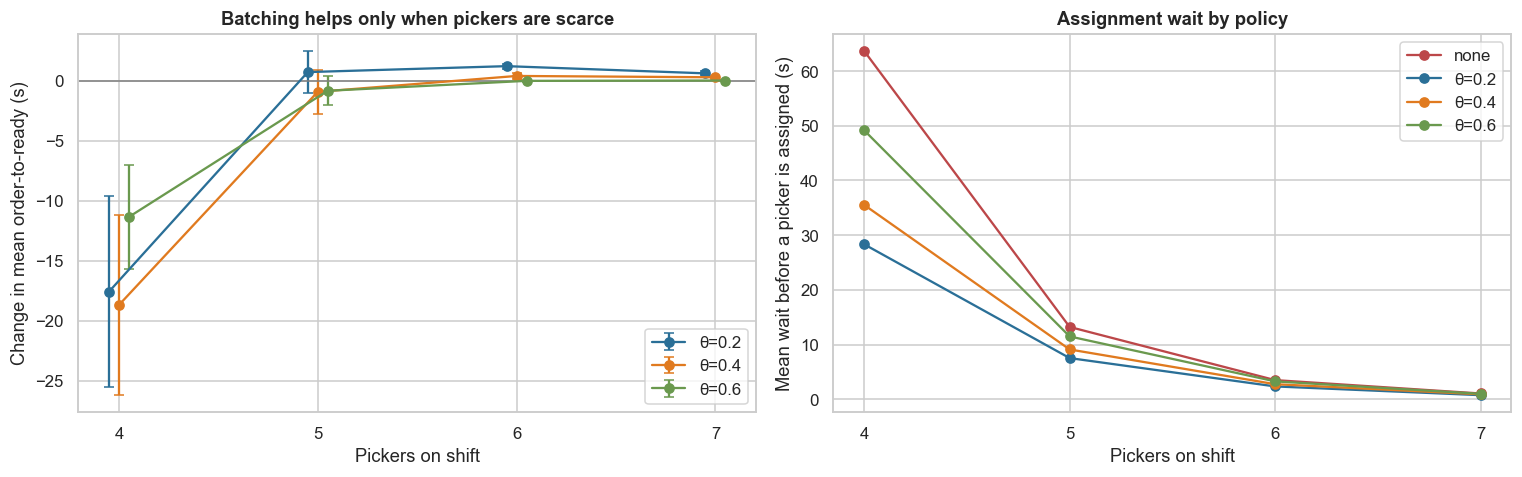

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5)); colors = {"θ=0.2": "#2a6f97", "θ=0.4": "#e07a1f", "θ=0.6": "#6a994e"}
for pol, col in colors.items():
    s_ = bs[bs.policy == pol]; axes[0].errorbar(s_.pickers + {"θ=0.2": -0.05, "θ=0.4": 0, "θ=0.6": 0.05}[pol], s_["Δ order-to-ready (s)"], yerr=[s_["Δ order-to-ready (s)"] - s_["CI low"], s_["CI high"] - s_["Δ order-to-ready (s)"]], marker="o", capsize=3, color=col, label=pol)
axes[0].axhline(0, color="grey", lw=1); axes[0].set_xlabel("Pickers on shift"); axes[0].set_ylabel("Change in mean order-to-ready (s)"); axes[0].set_title("Batching helps only when pickers are scarce"); axes[0].set_xticks(KS); axes[0].legend()
for pol, col in (("none", "#bc4749"),) + tuple(colors.items()):
    s_ = bt[bt.policy == pol].groupby("pickers").assign_wait.mean(); axes[1].plot(s_.index, s_.values, marker="o", color=col, label=pol)
axes[1].set_xlabel("Pickers on shift"); axes[1].set_ylabel("Mean wait before a picker is assigned (s)"); axes[1].set_title("Assignment wait by policy"); axes[1].set_xticks(KS); axes[1].legend()
plt.tight_layout(); plt.show()

**Takeaway:** the left panel shows all the benefit sitting at 4 pickers and nothing above 5. A looser similarity threshold (0.2 or 0.4) gains more than a strict one (0.6) at the same staffing because more pairs qualify. The right panel shows the wait for assignment is the part batching relieves; the policy works as a surge valve for under-staffed pods, not as an always-on rule.

## 8. ML Section — what we built and what is beyond it

The two ML pieces are small by design. **M2** (gradient boosting) is the forecaster of 7.1. Here we add the model the newsvendor logic actually wants: a **quantile gradient-boosted model** trained directly at each category's critical ratio (no distribution assumed), and compare three ordering rules head to head on the twin, all on **all 48 pods** with no tuning on the test data: (A) the legacy rule (M2 forecast × category buffer), (B) newsvendor on the M2 mean with a fitted negative binomial at q = CR, (C) quantile GBM at q = CR. The Wilcoxon test is paired by pod (Holm across 3 comparisons).

#### Code

In [17]:
qc = np.clip(CRcat, 0.5, 0.995); Tq = np.zeros((N, nd_te)); t0 = time.time()
for c in range(6):
    mq = HistGradientBoostingRegressor(loss="quantile", quantile=float(qc[c]), max_iter=150, learning_rate=0.1, random_state=SEED); s = vtr & (Xtr.cat.values == c); mq.fit(Xtr[s], ytr[s])
    sel = Xte.cat.values == c; pred = np.zeros(len(Xte)); pred[sel] = mq.predict(Xte[sel]); Tq += pred.reshape(N, nd_te) * (cat_n[:, None] == c)
print(f"6 quantile models fitted in {time.time() - t0:.0f}s | q by category: {dict(zip([c.split(' and')[0][:9] for c in gen.CAT_NAMES], qc.round(3)))}")
Tq = np.maximum(np.ceil(Tq), 1); Tnb_cr = np.maximum(nbinom.ppf(qc[cat_n][:, None], r_row, r_row / (r_row + Fte2)), 1)
pol = {"A legacy buffer × M2": T_fix(1.0) * 0 + np.maximum(np.ceil(Fte2 * BUF), 1), "B newsvendor NB at q = CR": Tnb_cr, "C quantile GBM at q = CR": Tq}
EP = {k: econ(replay(T)) for k, T in pol.items()}; base = "A legacy buffer × M2"; rows = []; pp_ = []
for k, E in EP.items():
    pp = E["profit"].sum(1) / (nd_te - MEAS); d = pp - EP[base]["profit"].sum(1) / (nd_te - MEAS); p = stats.wilcoxon(d).pvalue if k != base else np.nan; pp_.append(p)
    rows.append((k, pp.mean(), d.mean(), *ci_mean(d)[1:], E["avail"].mean() * 100, E["wval"].sum() / E["gmv"].sum() * 100, p))
ml = pd.DataFrame(rows, columns=["rule", "₹ profit / pod-day (120 SKUs)", "Δ vs legacy", "CI low", "CI high", "availability %", "wastage % of sales value", "Wilcoxon p"]).set_index("rule")
ml.loc[ml.index[1:], "p_holm"] = multipletests(ml["Wilcoxon p"].values[1:], method="holm")[1]
d_bc = (EP[list(pol)[2]]["profit"].sum(1) - EP[list(pol)[1]]["profit"].sum(1)) / (nd_te - MEAS); print(f"C − B profit per pod-day: mean ₹{d_bc.mean():,.0f}, Wilcoxon p = {stats.wilcoxon(d_bc).pvalue:.2g}")
ml.round(3)

6 quantile models fitted in 55s | q by category: {'Bakery': np.float64(0.54), 'Fresh pro': np.float64(0.5), 'Dairy': np.float64(0.5), 'Packaged ': np.float64(0.957), 'Snacks': np.float64(0.958), 'Home': np.float64(0.964)}


C − B profit per pod-day: mean ₹1,289, Wilcoxon p = 5.8e-10


,₹ profit / pod-day (120 SKUs),Δ vs legacy,CI low,CI high,availability %,wastage % of sales value,Wilcoxon p,p_holm
rule,,,,,,,,
A legacy buffer × M2,"1,715.1030",0.0000,0.0000,0.0000,83.7100,4.7060,NaN,NaN
B newsvendor NB at q = CR,"3,963.0030","2,247.9010","2,081.4780","2,399.4360",86.2660,2.1460,0.0000,0.0000
C quantile GBM at q = CR,"5,252.0750","3,536.9720","3,368.6840","3,685.1210",89.7060,3.2690,0.0000,0.0000


**Observation:** the **quantile gradient-boosted model at each category's critical ratio (C)** earned **₹5,252 per pod-day** against ₹1,715 for the legacy rule (+₹3,537, CI ₹3,369 to ₹3,685; Holm p < 1e-10) and ₹3,963 for the negative-binomial newsvendor (B, +₹2,248). C had higher availability (89.7% vs 83.7% for A and 86.3% for B) but more wastage than B (3.3% vs 2.1% of sales value), still lower than A (4.7%). C beat B by ₹1,289 per pod-day (p = 5.8e-10). Two cautions: the quantile level for produce and dairy was clipped to 0.5 because their critical ratios are below 0.5, which 7.3 showed is the wrong level for 2 to 3 day items; and the gap between A and the others is partly a weak legacy rule, not only the method.

- **What is not ML here:** the order rule is an optimisation on top of a forecast; the documented PO-buffer model is a second ML model, undisclosed beyond its role.
- **Beyond this notebook:** hierarchical and probabilistic forecasts (Case 12), censoring-aware training (Case 7), joint assortment and replenishment, multi-day shelf-life dynamic programs, and reinforcement-learning dispatch for picking (Case 4).
- **No tuning** (per the brief): learning rate 0.1, 150 to 200 iterations, defaults otherwise.

## 9. Business Translation — ₹ impact

Assumptions (D-03-08, none documented by Swiggy): **400 pods** at scale, each with ₹6 lakh of daily sales; our 120 simulated SKUs are scaled up to the pod's full sales by the ratio of the pod's sales to the simulated sales. The **planning uplift** is the profit gain of the best rule over the legacy rule, expressed as a share of simulated sales and applied to the pod's sales. The **picking saving** applies only if batching lets a pod run one picker fewer at the same order-to-ready time, at ₹95 per picker-hour over a 16-hour day, minus the extra packing errors at ₹120 each. The simulated gain is large because the legacy rule is weak on this data, so only a **haircut share survives: 15% (worst), 25% (base), 35% (best)** (our assumption, not measured). Best and worst also use the 95% CI on the uplift, with 600 and 150 pods.

#### Code

In [18]:
best_rule = ml["Δ vs legacy"].idxmax(); d_pod = EP[best_rule]["profit"].sum(1) / (nd_te - MEAS) - EP[base]["profit"].sum(1) / (nd_te - MEAS)
gmv_pod_day = EP[base]["gmv"].sum() / (gen.N_PODS * (nd_te - MEAS)); share = ml.loc[best_rule, ["Δ vs legacy", "CI low", "CI high"]] / gmv_pod_day
POD_GMV = 6e5; DAYSY = 365
REAL = {"worst": 0.15, "base": 0.25, "best": 0.35}   # share of the simulated gain assumed to survive in reality (sim-to-real haircut)
scen = {"worst": (150, max(share["CI low"], 0.0)), "base": (400, share["Δ vs legacy"]), "best": (600, share["CI high"])}
plan = {k: n * POD_GMV * s * REAL[k] * DAYSY / 1e7 for k, (n, s) in scen.items()}
# picking: smallest staffing at which batching (best theta) matches the unbatched order-to-ready of one more picker
best_th = bs.loc[bs["Δ order-to-ready (s)"].idxmin(), "policy"]; saved = 0.0; note = "no setting found"
for K in KS[:-1]:
    b_k = bs[(bs.pickers == K) & (bs.policy == best_th)].iloc[0]; nxt = bs[(bs.pickers == K + 1) & (bs.policy == best_th)].iloc[0]
    if b_k["baseline order-to-ready (s)"] + b_k["Δ order-to-ready (s)"] <= nxt["baseline order-to-ready (s)"] + 1.0: saved = 1.0; note = f"{best_th} at {K} pickers matches no batching at {K + 1}"; break
err_cost = float(bs[(bs.policy == best_th) & (bs.pickers == 4)]["Δ errors/day"].mean()) * 120
pick_cr = {k: (n * (saved * 16 * 95 - max(err_cost, 0)) * DAYSY / 1e7 if saved > 0 else 0.0) for k, (n, s) in scen.items()}
money = pd.DataFrame({"pods": {k: v[0] for k, v in scen.items()}, "simulated uplift (% of sales)": {k: v[1] * 100 for k, v in scen.items()}, "realisation haircut": REAL, "planning ₹ crore / yr": plan, "picking ₹ crore / yr": pick_cr}).T
money.loc["total ₹ crore / yr"] = money.loc["planning ₹ crore / yr"] + money.loc["picking ₹ crore / yr"]
print(f"Best rule: {best_rule} | simulated sales per pod-day (120 SKUs) ₹{gmv_pod_day:,.0f} | planning Δ profit ₹{d_pod.mean():,.0f} per pod-day (= {share['Δ vs legacy'] * 100:.2f}% of sales) | picking: {note}; extra error cost ₹{err_cost:,.0f} per pod-day")
money.round(3)

Best rule: C quantile GBM at q = CR | simulated sales per pod-day (120 SKUs) ₹78,708 | planning Δ profit ₹3,537 per pod-day (= 4.49% of sales) | picking: no setting found; extra error cost ₹28 per pod-day


,worst,base,best
pods,150.0000,400.0000,600.0000
simulated uplift (% of sales),4.2800,4.4940,4.6820
realisation haircut,0.1500,0.2500,0.3500
planning ₹ crore / yr,21.0900,98.4140,215.3260
picking ₹ crore / yr,0.0000,0.0000,0.0000
total ₹ crore / yr,21.0900,98.4140,215.3260


**Takeaway (business reading):** the best rule (quantile GBM at critical ratio) raises simulated profit by **₹3,537 per pod-day, 4.49% of simulated sales** (CI 4.28% to 4.68%). That is implausibly large to bank directly, so the case applies a **realisation haircut of 25% (15% worst, 35% best)**. Base: **₹98.4 crore a year** (400 pods); worst ₹21.1 crore (150 pods, CI low, 15%); best ₹215.3 crore (600 pods, CI high, 35%). **Picking contributes ₹0**: no staffing level lets batching match the unbatched time of one more picker, so no picker-hours are saved, and the 4-picker case adds ₹28 per pod-day of packing errors. The number is driven by the assumed pod sales (₹6 lakh a day), pod count and haircut, none documented by Swiggy.

## 10. Recommendation and Decision

**Recommendation**

1. **Order by service level, per category.** Replace the fixed buffer with an order-up-to quantile from a probabilistic forecast; start with the quantile model at the critical ratio for **non-perishables and dairy**, where the gain was largest and clearest (Holm p < 0.001).
2. **Do not use the textbook critical ratio for 2 to 3 day items.** Choose their quantile by replaying candidates on a simulator or in a pod experiment (here 0.98 to 0.995 won); for 1-day bakery items the fixed buffer and the newsvendor are equal (p = 0.12), so keep the simpler rule. Keep the fixed buffer for **fresh produce**, where it did better (-₹68 for the newsvendor).
3. **Judge forecast models by simulated availability and wastage, not wMAPE alone.** wMAPE on high-availability days flipped the ranking here. Use EA/EW as a screen, but treat a pod experiment as the decision.
4. **Run the pod experiment properly:** at least **8 pods per arm after adjusting for pre-period availability (21 raw; 19 if randomised by cluster) to detect 1 pp**. The 24 v 24 design here detects only 0.56 pp.
5. **Batching is a surge valve, not a default.** Allow batches of up to 2 (similarity 0.2 to 0.4) only when pickers are scarce; do not count on it to remove a picker.

**Decision rule:** ship a new ordering rule to a category if its replayed or experimental profit gain is positive with a 95% CI above zero **and** availability meets the category target. Roll back a pod cluster if availability falls more than 1 pp below the control for 3 consecutive days.

**KPIs:** availability by category against target; wastage % of sales value; profit per pod-day; share of days below 75% availability; fill rate by vendor; order-to-ready p50 and p90; assignment wait; packing errors per 1,000 orders; share of orders batched.

**Caveats:** simulated data; the assumed 50% goodwill cost and the legacy rule drive the size of the gain; the dispersion fit is optimistic; the grid for non-perishables was too narrow.

## 11. Risks, Limitations and Next Steps

- **Simulated demand and costs:** dispersion, margins, shelf lives, the 50% goodwill cost and category targets are assumptions; the newsvendor gain depends on how noisy demand really is and on the true cost of a lost sale. Re-estimate on real pod logs.
- **Dispersion fit is optimistic:** the fit used days with availability ≥ 95%, which are lower-demand days, so the buffer can be too small for volatile items. A censoring-aware fit (Case 7) is the fix.
- **One-day EA ignores carry-over and multi-day shelf life:** it is exact for 1-day items only; the full replay (7.3, 7.4) is the more honest metric where a simulator exists.
- **The textbook critical ratio is not the full story:** for items with a 2 to 3 day life, leftovers are not lost, so the best quantile differs from the critical ratio (7.3).
- **Pod-level experiments are noisy:** 48 pods detect only large effects (7.5); cluster-level randomisation needs more.
- **Picking:** the simulator assumes steady staffing, a fixed layout and the stated time and error parameters; the documented post gives no numbers. Unmodelled: picker fatigue, pack-station queues, rider arrival timing (Case 4).
- **Next steps:** run the 50-50 pod experiment on the best rule per perishable category first; fit dispersion with a censoring-aware method; add vendor lead-time variability and multi-day horizons; learn the batch cap k from a live test.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Critical ratio | CR = Cu ÷ (Cu + Co); order up to the demand quantile at CR |
| Cu, Co (here) | Cu = price − cost + 0.50 × price; Co = purchase cost (perishables), 10 days of holding (non-perishables) |
| Negative-binomial demand | mean μ, variance μ + μ²/r; target = NB quantile at q |
| wMAPE | Σ\|F − y\| ÷ Σ y |
| Availability | share of the 16 open hours with stock |
| Simple EA | min(1, A × predicted stock ÷ sales) |
| Hourly EA | hours until cumulative hourly sales reach the predicted stock; else observed in-stock hours + (stock − sales) ÷ median hourly sales, divided by 16 |
| Time to pack | setup + t_item × items + t_zone × zones + pack; batch adds a sorting step |
| Sample size (two means) | n per arm = 2 (1.96 + 0.84)² σ² ÷ δ² |
| Design effect | 1 + (m − 1) × ICC, m = pods per cluster |
| Zone Jaccard | \|Z₁ ∩ Z₂\| ÷ \|Z₁ ∪ Z₂\| |

| Term | Meaning |
|---|---|
| Pod / dark store | Small fulfilment warehouse serving a few kilometres |
| Newsvendor | Order once under demand uncertainty; balance the cost of too few against too many |
| Censored demand | Sales stop at stock-out, so sales understate demand |
| Fill rate | Share of ordered units the vendor delivers |
| EA / EW | Estimated availability / wastage if a prediction had been used |
| Leakage | Estimating a model on pods where it already controlled stock |
| ANCOVA | Regression of the outcome on the arm and a pre-period covariate |
| Order-to-ready | Seconds from order placed to packed and ready |